# Developer Pay-Tier Classification: Traditional ML vs Deep Learning

**Mission.** Reduce youth unemployment and underpayment in Rwanda by giving young people evidence about which skills and choices go with better pay in software careers.

**Problem statement.** Given a developer's profile (experience, education, skills, role, how they learned to code, work setup), can we predict their **compensation tier relative to peers in their country** (`Low` / `Mid` / `High`), and which factors separate the low-pay from the high-pay tier?

**Dataset.** Stack Overflow Annual Developer Survey 2023, 2024 and 2025 (open CSVs from the `StackExchange/Survey` GitHub repository), pooled: **203,812 raw rows**.

| Link | URL |
|---|---|
| GitHub repository | _add link_ |
| Google Drive (raw data zip + best models) | _add link_ |
| Demo video | _add link_ |

**How to run.** Create the environment (`python -m venv .venv`, then `pip install -r requirements.txt`), open this notebook from the `notebooks/` folder and choose **Restart → Run All**. The first run downloads the raw CSVs into `data/` (not committed to git). All logic lives in `src/`; this notebook only orchestrates and explains.

**Reproducibility.** Every random step uses `seed = 42`. Each experiment is saved by `ExperimentTracker` (model file, settings JSON, one row in `results/experiments.csv`, TensorBoard scalars in `logs/`). A rerun with unchanged code, data and settings **reloads** the saved model instead of refitting, and the last section refits on purpose to prove the numbers come out the same.

## 2. Setup

**Purpose.** Make `src/` importable, turn on auto-reload (edits in `src/` are picked up without restarting), fix the random seeds and print the library versions used for the results.

**What to look for.** The versions printed here are the ones also stored in every `results/settings/exp_*.json`.

In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.experiments import set_seeds, library_versions

SEED = 42
set_seeds(SEED)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
warnings.filterwarnings("ignore", category=FutureWarning)
FIG = "../figures"
library_versions()

{'python': '3.14.7',
 'numpy': '2.5.4',
 'pandas': '3.0.6',
 'scikit-learn': '1.9.1',
 'tensorflow': '2.22.0-rc0'}

## 3. Data loading and size check

**Purpose.** Download (first run only) and load the three survey years, then count raw rows, rows with a salary, and Rwanda rows.

**Method.** `load_years()` reads `data/survey_{year}.csv` (with `low_memory=False` so pandas reads each column with one consistent type). `harmonize()` keeps only the columns that exist in **all three** years and adds a `Year` column, so the years can be stacked into one table.

**Expected output.** About 203,812 raw rows. That is well above the 20,000-row requirement.

In [2]:
from src.data_loading import load_years, harmonize

frames = load_years()
for y, d in frames.items():
    print(y, d.shape,
          "| with salary:", d["ConvertedCompYearly"].notna().sum(),
          "| Rwanda rows:", (d["Country"] == "Rwanda").sum())
print("Raw rows (all years):", sum(len(d) for d in frames.values()))

df = harmonize(frames)
print("\nPooled table:", df.shape, "-> shared columns (excluding Year):", df.shape[1] - 1)

2023 (89184, 84) | with salary: 48019 | Rwanda rows: 27
2024 (65437, 114) | with salary: 23435 | Rwanda rows: 22
2025 (49191, 172) | with salary: 23947 | Rwanda rows: 15
Raw rows (all years): 203812

Pooled table: (203812, 38) -> shared columns (excluding Year): 37


**Interpretation.** The three years give **203,812 raw rows** (2023: 89,184; 2024: 65,437; 2025: 49,191). Only **37 columns are shared** by all three years, because each year asked a different set of questions (2025 alone has 172 columns). Rwanda has only 64 raw rows (27 + 22 + 15), far too few to model, so Rwanda is used as a descriptive case study, not as a modelling target.

## 4. Exploration

**Purpose.** Understand who answered the salary question, how much is missing per survey year, and what the salary distribution looks like. This tells us which filters and which features are safe to use.

**Method.** We look only at respondents who reported a salary (the rows that can get a label). We print (1) the `MainBranch` and `Employment` mix, (2) the share of missing values per column per year, and (3) salary percentiles. We also plot salary on a log scale, because salaries span three orders of magnitude.

In [3]:
lab = df[df["ConvertedCompYearly"].notna()].copy()
print("Labelled rows:", len(lab))
print(lab["MainBranch"].value_counts(), "\n")
print(lab["Employment"].value_counts().head(8))

Labelled rows: 95401
MainBranch
I am a developer by profession                                                                86098
I am not primarily a developer, but I write code sometimes as part of my work/studies          7738
I used to be a developer by profession, but no longer am                                        498
I work with developers or my work supports developers but am not a developer by profession      390
I am learning to code                                                                           363
I code primarily as a hobby                                                                     314
Name: count, dtype: int64 

Employment
Employed, full-time                                                         56887
Employed                                                                    19500
Independent contractor, freelancer, or self-employed                         8580
Employed, full-time;Independent contractor, freelancer, or self-employed     4983
E

In [4]:
# Share missing per column and year (labelled rows only), worst columns first
feature_cols = [c for c in df.columns
                if c not in ["ResponseId", "CompTotal", "Currency", "ConvertedCompYearly", "Year"]]
miss = lab.groupby("Year")[feature_cols].apply(lambda g: g.isna().mean()).T.round(2)
miss.sort_values(2025, ascending=False).head(20)

Year,2023,2024,2025
WebframeWantToWorkWith,0.32,0.31,0.46
PlatformWantToWorkWith,0.37,0.37,0.40
DatabaseWantToWorkWith,0.27,0.24,0.40
OfficeStackAsyncWantToWorkWith,0.32,0.27,0.31
WebframeHaveWorkedWith,0.21,0.21,0.31
LearnCode,0.00,0.00,0.29
PlatformHaveWorkedWith,0.22,0.24,0.25
DatabaseHaveWorkedWith,0.13,0.13,0.23
LanguageWantToWorkWith,0.07,0.06,0.21
OpSysProfessional use,0.06,0.06,0.13


count       95401.0
mean        98607.0
std        543922.0
min             1.0
1%            174.0
5%           4365.0
25%         40061.0
50%         72821.0
75%        119631.0
95%        225000.0
99%        400000.0
max      74351432.0
Name: ConvertedCompYearly, dtype: float64


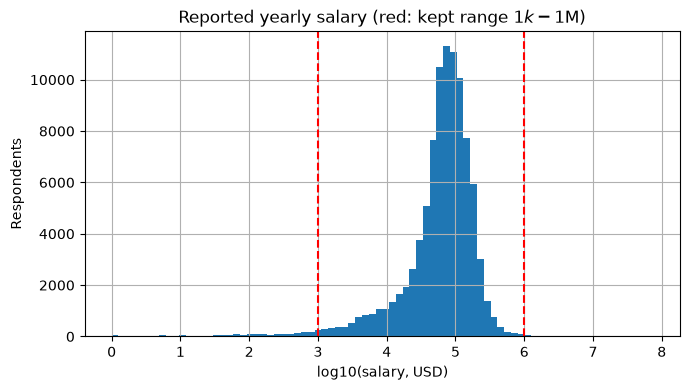

In [5]:
print(lab["ConvertedCompYearly"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(0))

fig, ax = plt.subplots(figsize=(7, 4))
np.log10(lab["ConvertedCompYearly"].clip(lower=1)).hist(bins=80, ax=ax)
for v in (1_000, 1_000_000):
    ax.axvline(np.log10(v), color="red", ls="--")
ax.set(xlabel="log10(salary, USD)", ylabel="Respondents",
       title="Reported yearly salary (red: kept range $1k-$1M)")
plt.tight_layout(); plt.savefig(f"{FIG}/salary_distribution.png", dpi=200); plt.show()

**Interpretation.** - **95,401** respondents reported a salary. **86,098 (90%)** of them are professional developers, so keeping only that group loses little data and makes people comparable.
- Some missingness is **by survey design**, not by respondent choice: `LearnCode` is complete in 2023/24 but 29% missing in 2025; `ICorPM` is 31-32% missing in 2023/24 but only 13% in 2025. A model could learn "missing" as a proxy for the survey year, which we must watch for.
- The `...WantToWorkWith` columns are 24-46% missing and describe wishes, not experience, so they are not used.
- Salary is extremely skewed: median **$72,821**, but the minimum is $1 and the maximum $74.4M, and 1% of rows report under $174 a year. These are almost certainly entry errors, which is why we keep $1,000-$1,000,000.

## 5. Cleaning and target construction

**Purpose.** Keep a comparable population and build the target `PayTier`.

**Method (`clean_and_label`).**
1. Keep respondents with a salary.
2. Keep professional developers (`MainBranch == "I am a developer by profession"`).
3. Keep full-time employees. In 2023/24 the answer is "Employed, full-time"; in 2025 the survey only says "Employed", so both are accepted.
4. Keep salaries between \$1,000 and \$1,000,000 to remove obvious typos (e.g. a monthly figure entered as yearly).
5. Keep countries with at least 100 rows, so a country's tercile cut-offs are not based on a handful of people.
6. **Label:** within each country, rank salaries and cut them into thirds: `Low`, `Mid`, `High`. The tiers are **relative to the country**, so a developer in Rwanda and one in the USA are each compared with their own market, not converted to one global scale.

**Why terciles?** Equal-sized classes make accuracy easy to read (chance = 33%) and avoid class imbalance. **Known risk:** the target is made by binning a numeric salary; this must be justified in the report and confirmed with the instructor.

**Expected output.** A funnel table (goes in the report), tier balance overall and by year, and how many African rows survive.

In [6]:
from src.preprocessing import clean_and_label

data, funnel = clean_and_label(df)
funnel["Dropped"] = funnel["Rows"].shift(1) - funnel["Rows"]
print(funnel.to_string(index=False), "\n")
print("Countries kept:", data["Country"].nunique())
print("\nTier balance:\n", data["PayTier"].value_counts(normalize=True).round(3))
print("\nTier balance by year:\n", pd.crosstab(data["Year"], data["PayTier"], normalize="index").round(3))

AFRICA = ["Rwanda", "Kenya", "Nigeria", "Uganda", "Ghana", "South Africa", "Ethiopia", "Tanzania"]
print("\nAfrican countries kept:\n", data[data["Country"].isin(AFRICA)].groupby("Country").size())

                        Step   Rows  Dropped
             Raw pooled rows 203812      NaN
     Respondents with salary  95401 108411.0
         Selected MainBranch  86098   9303.0
          Employed full-time  75357  10741.0
Salary in [1,000, 1,000,000]  74014   1343.0
   Countries with >=100 rows  71612   2402.0 

Countries kept: 63

Tier balance:
 PayTier
High    0.334
Mid     0.333
Low     0.333
Name: proportion, dtype: float64

Tier balance by year:
 PayTier    Low    Mid   High
Year                        
2023     0.342  0.342  0.316
2024     0.356  0.328  0.316
2025     0.285  0.319  0.395

African countries kept:
 Country
Nigeria         142
South Africa    533
dtype: int64


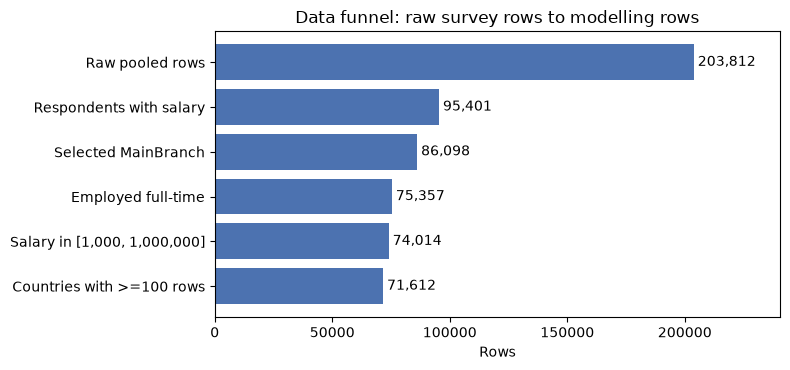

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(funnel["Step"][::-1], funnel["Rows"][::-1], color="#4C72B0")
for i, v in enumerate(funnel["Rows"][::-1]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set(xlabel="Rows", title="Data funnel: raw survey rows to modelling rows")
ax.set_xlim(0, funnel["Rows"].max() * 1.18)
plt.tight_layout(); plt.savefig(f"{FIG}/data_funnel.png", dpi=200); plt.show()

**Interpretation.** - The funnel goes **203,812 → 95,401 → 86,098 → 75,357 → 74,014 → 71,612** rows in 63 countries. The biggest drop is the 108,411 respondents with no salary (the question is optional).
- Tiers are balanced overall (33.3-33.4% each), as terciles should be.
- **Drift by year:** 2025 has 28.5% Low and 39.5% High, against about 34/34/32 in 2023. Tiers are pooled over years, so 2025 respondents sit higher within their country. Therefore `Year` is **never a feature** (it would learn survey drift, not skills), and accuracy is reported per year.
- Of the African countries, only **South Africa (533)** and **Nigeria (142)** pass the 100-row rule.

## 6. Feature engineering and plausibility checks

**Purpose.** Turn text answers into numbers a model can use, and remove impossible values.

**Method (`add_basic_features`).**
- `Age_num`: midpoint of the age bracket (e.g. "25-34 years old" → 30). "Prefer not to say" → missing.
- `YearsCode_num`: "Less than 1 year" → 0.5, "More than 50 years" → 51. `WorkExp_num` is already numeric.
- **Plausibility check:** a value is masked to missing if it exceeds 51 years, or exceeds (oldest age in the person's bracket − earliest plausible start age: 5 for coding, 14 for work). The raw data contained values up to 100.
- `EdLevel_ord`: education as an ordered number 1–7 (primary → professional degree). "Something else" → missing.
- `WorkExp_missing`: 1 if work experience is unknown (computed **after** masking).
- `IsYouth`: under 25. Used only to **evaluate** the model on young people, not as a model input.

**Why no leakage?** These are fixed rules written by hand; nothing is learned from the data, so applying them before the split cannot leak information from validation/test into training.

In [8]:
from src.features import add_basic_features

data = add_basic_features(data)
print("Implausible year values masked:", data.attrs["n_implausible_years"])

num_cols = ["Age_num", "YearsCode_num", "WorkExp_num", "EdLevel_ord"]
print(data[num_cols].describe().round(1), "\n")
print("Missing after masking:\n", data[num_cols].isna().sum(), "\n")
print("Youth rows (under 25):", int(data["IsYouth"].sum()))

Implausible year values masked: 113
       Age_num  YearsCode_num  WorkExp_num  EdLevel_ord
count  71579.0        71439.0      56101.0      70939.0
mean      35.2           15.8         11.7          5.0
std        9.5            9.7          8.8          1.2
min       17.0            0.5          0.0          1.0
25%       30.0            9.0          5.0          5.0
50%       30.0           13.0         10.0          5.0
75%       40.0           20.0         16.0          6.0
max       67.0           51.0         50.0          7.0 

Missing after masking:
 Age_num             33
YearsCode_num      173
WorkExp_num      15511
EdLevel_ord        673
dtype: int64 

Youth rows (under 25): 7689


In [9]:
# Education answers by year: the 2025 survey dropped "Something else"
pd.crosstab(data["EdLevel"].fillna("(blank)"), data["Year"])

Year,2023,2024,2025
EdLevel,,,
(blank),0,0,10
"Associate degree (A.A., A.S., etc.)",1282,577,531
"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",18572,8234,7526
"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",10124,5211,4724
Other (please specify):,0,0,125
Primary/elementary school,136,78,55
"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",1444,705,721
"Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)",1627,778,650
Some college/university study without earning a degree,4292,1980,1692


**Interpretation.** - **113** impossible experience values were masked. After masking, the maxima are 51 coding years and 50 working years.
- `WorkExp_num` is missing for 15,511 rows (22%). This is almost entirely 2023/24 (28% and 27% missing) against 0.9% in 2025, so `WorkExp_missing` partly encodes the year. `YearsCode_num` (only 173 missing) is the more reliable experience signal.
- 7,689 rows (10.7%) are youth (under 25).
- The crosstab shows "Something else" exists only in 2023/24 and "Other (please specify):" only in 2025. Both map to missing, so `EdLevel_ord` means the same thing in every year.

## 7. Train / validation / test split

**Purpose.** Hold out data the models never learn from.

**Method (`make_splits`).** 70% train, 15% validation, 15% test, **stratified on Year + PayTier** so every split has the same mix of years and tiers. All tuning uses the training set (cross-validation) or the validation set. The **test set is used once**, at the very end, for the final chosen models.

In [10]:
from src.splits import make_splits
from src.pipeline import TARGET

train, val, test = make_splits(data, seed=SEED)
print("Sizes:", {n: len(p) for n, p in [("train", train), ("val", val), ("test", test)]})
pd.DataFrame({n: p[TARGET].value_counts(normalize=True).round(3)
              for n, p in [("train", train), ("val", val), ("test", test)]})

Sizes: {'train': 50128, 'val': 10742, 'test': 10742}


,train,val,test
PayTier,,,
High,0.334,0.334,0.334
Mid,0.333,0.333,0.333
Low,0.333,0.333,0.333


**Interpretation.** Train 50,128 / validation 10,742 / test 10,742 rows, with identical tier shares (33.3-33.4%) in each split. Chance accuracy is therefore about 33%, and the majority-class baseline in experiment 0 should land there.

## 8. Preprocessing pipeline check

**Purpose.** Confirm what the models actually see.

**Method (`build_preprocessor`, a scikit-learn `ColumnTransformer`).**
- **Numeric** (`Age_num`, `YearsCode_num`, `EdLevel_ord`, `WorkExp_num`, `WorkExp_missing`): fill missing with the training median, then standardise.
- **Multi-select skills** (`LanguageHaveWorkedWith`, `DatabaseHaveWorkedWith`, `PlatformHaveWorkedWith`, `WebframeHaveWorkedWith`, `DevType`, `LearnCode`): `MultiHotEncoder` creates one 0/1 column per answer that appears in at least 1% of **training** rows. Rare answers are dropped; answers never seen in training are ignored.
- **Optional categoricals** (job context: `OrgSize`, `RemoteWork`, `ICorPM`, `Industry`; or `Country`): fill with "Unknown", one-hot encode.
- **Everything else is dropped** (`remainder="drop"`), including salary, currency, `Year` and `ResponseId`, so the label cannot leak into the features.

Because the preprocessor sits **inside** each model `Pipeline`, it is re-fitted on the training rows (or on each training fold during cross-validation), which prevents leakage.

In [11]:
from src.pipeline import build_preprocessor, MULTI

pre = build_preprocessor().fit(train)
names = pre.get_feature_names_out()
enc = pre.named_transformers_["multi"]
print("Answers kept per multi-select column:", {c: len(v) for c, v in enc.vocab_.items()})
print("Total features:", len(names), "(5 numeric +", len(enc.feature_names_), "multi-hot)")
print("Example feature names:", list(names[:3]) + list(names[5:8]))

Answers kept per multi-select column: {'LanguageHaveWorkedWith': 36, 'DatabaseHaveWorkedWith': 26, 'PlatformHaveWorkedWith': 43, 'WebframeHaveWorkedWith': 29, 'DevType': 16, 'LearnCode': 20}
Total features: 175 (5 numeric + 170 multi-hot)
Example feature names: ['num__Age_num', 'num__YearsCode_num', 'num__EdLevel_ord', 'multi__LanguageHaveWorkedWith=Assembly', 'multi__LanguageHaveWorkedWith=Bash/Shell (all shells)', 'multi__LanguageHaveWorkedWith=C']


**Interpretation.** The core feature matrix has **175 columns**: 5 numeric plus 170 multi-hot answers (36 languages, 26 databases, 43 platforms, 29 web frameworks, 16 developer roles, 20 ways of learning to code). These are the inputs for experiments 0-5; later experiments add or remove groups to test what matters.

## 9. Traditional machine-learning experiments (0-6)

**How every experiment is run.** Each model is a scikit-learn `Pipeline` (preprocessor + classifier) passed to `tracker.run(...)`. The tracker:
1. seeds everything with 42,
2. fits on the **training set only** (or reloads the saved model if code, data and settings are unchanged),
3. scores train and validation, and
4. saves the model (`models/`), the full settings (`results/settings/exp_{id}.json`), one row in `results/experiments.csv` and TensorBoard scalars (`logs/sklearn/`).

**Metrics in the table.**
| Metric | Meaning | Why we need it |
|---|---|---|
| `accuracy` | share of rows with the correct tier | easy to read; chance = 33% |
| `macro_f1` | F1 averaged over Low, Mid and High equally | punishes a model that ignores one tier; **main selection metric** |
| `roc_auc_ovr` | one-vs-rest ROC-AUC, averaged over tiers | ranking quality, independent of the 0.5 threshold |
| `mean_tier_error` | average number of tiers off (0, 1 or 2) | the tiers are ordered: Low→High is worse than Low→Mid |
| `far_error_rate` | share of Low↔High confusions | the "badly wrong" errors |
| `youth_accuracy`, `youth_macro_f1` | the same, for respondents under 25 only | the mission group |

**Hyperparameter search.** `RandomizedSearchCV` with **stratified 5-fold cross-validation on the training set**, `scoring="f1_macro"`, `random_state=42`. The validation set is never used for fitting or searching, only for comparing experiments.

In [12]:
from scipy.stats import loguniform, randint, uniform
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

from src.experiments import ExperimentTracker
from src.evaluation import accuracy_by_group, subgroup_table

tracker = ExperimentTracker(train, val, target=TARGET, seed=SEED)
y_train, y_val = train[TARGET].astype(str), val[TARGET].astype(str)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

COLS = ["model", "val_accuracy", "val_macro_f1", "val_roc_auc_ovr", "train_accuracy",
        "train_macro_f1", "val_mean_tier_error", "val_far_error_rate",
        "val_youth_accuracy", "val_youth_macro_f1", "fit_seconds"]

def show(*ids):
    # Rows of the experiment table for the given experiment ids
    t = tracker.table()
    t["id"] = t["id"].astype(str)
    return t.set_index("id").loc[[str(i) for i in ids], COLS]

def search(pipe, params, n_iter, n_jobs=-1):
    # Randomized search over the whole pipeline, 5-fold CV on train, macro-F1.
    # n_jobs = parallel workers; each holds a copy of the data, so fewer workers = less memory
    return RandomizedSearchCV(pipe, params, n_iter=n_iter, cv=CV, scoring="f1_macro",
                              random_state=SEED, n_jobs=n_jobs, refit=True)

### Experiment 0: majority-class baseline

**Hypothesis.** A model that always predicts the most common training tier scores about 33% accuracy and a macro-F1 near 0.17. Any real model must beat this.

**Why run it?** It checks the split and the target (balanced terciles should give ~1/3) and gives the reference line for every later result.

In [13]:
dummy = tracker.run(0, "Majority class",
    Pipeline([("pre", build_preprocessor()),
              ("clf", DummyClassifier(strategy="most_frequent"))]),
    settings={"features": "core", "strategy": "most_frequent"},
    note="chance reference")
show(0)

[exp 0] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
0,Majority class,0.3336,0.1668,0.5,0.3336,0.1668,0.9994,0.3331,0.0645,0.0404,3.8


**Observation.** Accuracy **0.334** and macro-F1 **0.167**: exactly chance for three balanced classes, which confirms the split and the label. It always predicts the same tier, so it scores 0 on the other two (hence the low macro-F1), and its youth accuracy is only 0.065 because it predicts High while most young people are Low.

### Experiment 1: Logistic Regression on the core profile features

**What changes vs. exp 0.** A real, interpretable model: multinomial logistic regression with default regularisation (`C = 1`) on the 175 core features.

**Hypothesis.** Experience, education and skills carry real signal, so accuracy should clearly beat 33%. A linear model may underfit, which would show as **train ≈ validation** (high bias), not as a large train-validation gap.

In [14]:
logreg = tracker.run(1, "Logistic Regression",
    Pipeline([("pre", build_preprocessor()),
              ("clf", LogisticRegression(max_iter=2000, random_state=SEED))]),
    settings={"features": "core", "C": 1.0},
    note="interpretable benchmark")
display(show(0, 1))
print("Accuracy by year:\n", accuracy_by_group(logreg, val, y_val, val["Year"]))

[exp 1] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
0,Majority class,0.3336,0.1668,0.5000,0.3336,0.1668,0.9994,0.3331,0.0645,0.0404,3.8
1,Logistic Regression,0.5395,0.5289,0.7195,0.5458,0.5355,0.5561,0.0956,0.6766,0.3995,8.4


Accuracy by year:
 2023    0.536
2024    0.530
2025    0.558
dtype: float64


**Observation.** - Validation accuracy **0.540**, macro-F1 **0.529**, ROC-AUC **0.720**: well above chance, so the profile carries real signal about relative pay.
- Train accuracy 0.546 vs validation 0.540: a gap under 1 point. The model is **not overfitting; it underfits (high bias)**. A more flexible model or better features should help more than regularisation.
- Accuracy is similar across years (0.536 / 0.530 / 0.558), slightly higher in 2025.
- Youth: accuracy 0.677 and macro-F1 0.400 (looked at in detail in section 12).

### Experiment 2: Logistic Regression + job context

**What changes vs. exp 1.** Four employer/job columns are added: `OrgSize`, `RemoteWork`, `ICorPM` (individual contributor or manager) and `Industry`, one-hot encoded with an "Unknown" level. Everything else is identical.

**Hypothesis.** Company size and management roles are linked to pay, so the score should rise. **Risk:** `ICorPM` and `Industry` are mostly missing in 2023/24 but not in 2025, so "Unknown" can act as a hidden year flag. We check accuracy by year: a real gain should appear in every year, not only 2025.

In [15]:
logreg_ctx = tracker.run(2, "Logistic Regression + job context",
    Pipeline([("pre", build_preprocessor(use_job_context=True)),
              ("clf", LogisticRegression(max_iter=2000, random_state=SEED))]),
    settings={"features": "core + job context", "C": 1.0},
    note="does employer info add signal?")
display(show(1, 2))
pd.DataFrame({"exp1": accuracy_by_group(logreg, val, y_val, val["Year"]),
              "exp2": accuracy_by_group(logreg_ctx, val, y_val, val["Year"])})

[exp 2] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
1,Logistic Regression,0.5395,0.5289,0.7195,0.5458,0.5355,0.5561,0.0956,0.6766,0.3995,8.4
2,Logistic Regression + job context,0.5502,0.5421,0.7380,0.5619,0.5540,0.5316,0.0817,0.6664,0.4059,4.6


,exp1,exp2
2023,0.536,0.545
2024,0.530,0.552
2025,0.558,0.559


**Observation.** - Job context helps: accuracy 0.540 → **0.550**, macro-F1 0.529 → **0.542**, AUC 0.720 → 0.738, and fewer far errors (0.096 → 0.082).
- **By year the gain is uneven**: 2023 +0.9, 2024 +2.2, 2025 only +0.1 points. The gain sits in 2023/24, which is where `ICorPM` and `Industry` are mostly "Unknown". It is also where `OrgSize` and `RemoteWork` are fully answered (they are 11-12% missing in 2025), so the gain could come from real employer information. With a linear model we **cannot rule out** a partial year-proxy effect. Experiment 6f re-checks this with the tree model.
- Decision: later experiments use **core + job context**, with the year check repeated.

### Experiment 3: tuned Logistic Regression (regularisation)

**What changes vs. exp 2.** Same features as the better of exp 1/2. We now search the regularisation instead of using defaults: `C` (strength, log-uniform 0.001-100), `l1_ratio` (0 = L2/ridge, 1 = L1/lasso, in between = elastic net) and `class_weight` (none or balanced). Solver `saga` supports all of these. 20 random settings × 5 folds.

**Hypothesis.** Experiment 1 showed almost no train-validation gap, so the model is **not overfitting**. If that is right, tuning regularisation should change the score very little, which would tell us the limit is the **features or the model's linearity**, not regularisation.

In [16]:
best_lr_ctx = show(1, 2)["val_macro_f1"].idxmax() == "2"
lr_search = search(
    Pipeline([("pre", build_preprocessor(use_job_context=best_lr_ctx)),
              ("clf", LogisticRegression(solver="saga", max_iter=3000, random_state=SEED))]),
    {"clf__C": loguniform(1e-3, 1e2), "clf__l1_ratio": uniform(0, 1),
     "clf__class_weight": [None, "balanced"]},
    n_iter=20)
lr_tuned = tracker.run(3, "Logistic Regression (tuned)", lr_search,
    settings={"features": "core + job context" if best_lr_ctx else "core",
              "search": "C~logU(1e-3,1e2), l1_ratio~U(0,1), class_weight",
              "n_iter": 20, "cv": "stratified 5-fold"},
    note="is the limit regularisation?")
print("Best parameters:", lr_tuned.best_params_, "| CV macro-F1:", round(lr_tuned.best_score_, 4))
show(1, 2, 3)

[exp 3] hashes match -> loading saved model, no refit


Best parameters: {'clf__C': np.float64(0.0745934328572655), 'clf__class_weight': None, 'clf__l1_ratio': np.float64(0.1834347898661638)} | CV macro-F1: 0.5465


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
1,Logistic Regression,0.5395,0.5289,0.7195,0.5458,0.5355,0.5561,0.0956,0.6766,0.3995,8.4
2,Logistic Regression + job context,0.5502,0.5421,0.7380,0.5619,0.5540,0.5316,0.0817,0.6664,0.4059,4.6
3,Logistic Regression (tuned),0.5514,0.5428,0.7385,0.5615,0.5532,0.5298,0.0812,0.6698,0.4083,878.8


**Observation.** - Best setting: `C` ≈ 0.075 (stronger regularisation than the default 1), `l1_ratio` ≈ 0.18 (mostly ridge), no class weights. CV macro-F1 0.547.
- Validation macro-F1 moves only from 0.542 to **0.543**. As predicted from the tiny train-validation gap, **regularisation is not the bottleneck**: the linear model has reached its ceiling.
- Cost: 853 s for 100 `saga` fits, for a gain of 0.001. This motivates moving to non-linear models.

### Experiment 3b: linear Support Vector Machine

**Why a *linear* SVM.** A kernel SVM (`SVC`) needs time roughly between n² and n³ in the number of rows; with ~50,000 rows × 175 features it would take hours and much memory. `LinearSVC` solves the linear version in seconds, so it is the fair SVM to compare with logistic regression. It does not output probabilities, so it has **no ROC-AUC**.

**Hypothesis.** It is also a linear model, so it should land close to logistic regression.

In [17]:
svm = tracker.run("3b", "Linear SVM",
    Pipeline([("pre", build_preprocessor(use_job_context=best_lr_ctx)),
              ("clf", LinearSVC(C=0.1, random_state=SEED))]),
    settings={"features": "core + job context" if best_lr_ctx else "core", "C": 0.1},
    note="linear SVM; kernel SVM too slow at this size")
show(3, "3b")

[exp 3b] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
3,Logistic Regression (tuned),0.5514,0.5428,0.7385,0.5615,0.5532,0.5298,0.0812,0.6698,0.4083,878.8
3b,Linear SVM,0.5480,0.5214,NaN,0.5538,0.5271,0.5542,0.1022,0.6689,0.3835,8.0


**Observation.** The linear SVM reaches accuracy 0.548 but a lower macro-F1 (**0.521** vs 0.543) and more far errors (0.102 vs 0.081) than tuned logistic regression. Without probabilities it also gives no ROC-AUC and no probability ranking. It confirms the linear ceiling around 0.52-0.54 macro-F1, and logistic regression remains the better linear model.

### Experiment 4: Random Forest (non-linear, tuned)

**What changes vs. exp 3.** A different model family: many decision trees, each trained on a bootstrap sample, voting together. Trees can capture **interactions** (e.g. "Python *and* cloud platform *and* 10+ years") that a linear model cannot. Search: number of trees, depth, minimum leaf size, features per split. 12 settings × 5 folds.

**Hypothesis.** If the ceiling in exp 1-3 is the linear form, a forest should beat logistic regression. Forests can overfit, so expect a larger train-validation gap; deep trees especially.

In [18]:
rf_search = search(
    Pipeline([("pre", build_preprocessor(use_job_context=best_lr_ctx)),
              ("clf", RandomForestClassifier(random_state=SEED, n_jobs=1))]),
    {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 12, 20, 30],
     "clf__min_samples_leaf": [1, 3, 5, 10, 20], "clf__max_features": ["sqrt", 0.2, 0.35]},
    n_iter=12)
rf = tracker.run(4, "Random Forest (tuned)", rf_search,
    settings={"features": "core + job context" if best_lr_ctx else "core",
              "search": "n_estimators, max_depth, min_samples_leaf, max_features",
              "n_iter": 12, "cv": "stratified 5-fold"},
    note="is the ceiling model capacity?")
print("Best parameters:", rf.best_params_, "| CV macro-F1:", round(rf.best_score_, 4))
show(3, 4)

[exp 4] hashes match -> loading saved model, no refit


Best parameters: {'clf__n_estimators': 200, 'clf__min_samples_leaf': 1, 'clf__max_features': 0.2, 'clf__max_depth': None} | CV macro-F1: 0.5644


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
3,Logistic Regression (tuned),0.5514,0.5428,0.7385,0.5615,0.5532,0.5298,0.0812,0.6698,0.4083,878.8
4,Random Forest (tuned),0.5681,0.5632,0.7527,1.0000,1.0000,0.5004,0.0685,0.7105,0.3189,902.5


**Observation.** - Best forest: 200 trees, **no depth limit, leaf size 1**, 20% of features per split. CV macro-F1 0.564.
- Validation macro-F1 **0.563** (+0.020 over tuned LR) and AUC 0.753: the non-linear model breaks the linear ceiling, so interactions between features matter.
- **Train accuracy 1.000**: the trees memorise the training set, a textbook case of **high variance**. Averaging many trees still generalises, but the 43-point train-validation gap shows the forest is far more flexible than the signal requires.
- Youth macro-F1 falls to 0.319: the forest predicts "Low" for most young people.

### Experiment 5: Histogram Gradient Boosting (tuned)

**What changes vs. exp 4.** Boosting builds trees **one after another**, each correcting the errors of the previous ones, instead of averaging independent trees. It is usually the strongest classical method on tabular data. Search: learning rate, tree size (`max_leaf_nodes`, `max_depth`), minimum leaf size and L2 penalty. Up to 500 boosting rounds with **early stopping** on an internal 10% split of the training fold. 20 settings × 5 folds.

**Hypothesis.** Gradient boosting matches or beats the random forest with a smaller train-validation gap, because early stopping and a small learning rate control overfitting.

In [19]:
hgb_search = search(
    Pipeline([("pre", build_preprocessor(use_job_context=best_lr_ctx)),
              ("clf", HistGradientBoostingClassifier(max_iter=500, early_stopping=True,
                                                     n_iter_no_change=20, random_state=SEED))]),
    {"clf__learning_rate": loguniform(0.02, 0.3), "clf__max_leaf_nodes": [15, 31, 63],
     "clf__max_depth": [None, 4, 6, 8], "clf__min_samples_leaf": [20, 50, 100],
     "clf__l2_regularization": loguniform(1e-4, 10)},
    n_iter=20, n_jobs=4)  # 4 workers: each boosting fit is itself multi-threaded
hgb = tracker.run(5, "HistGradientBoosting (tuned)", hgb_search,
    settings={"features": "core + job context" if best_lr_ctx else "core",
              "search": "learning_rate, max_leaf_nodes, max_depth, min_samples_leaf, l2",
              "n_iter": 20, "cv": "stratified 5-fold", "early_stopping": "10% of train fold"},
    note="strongest classical model?")
print("Best parameters:", hgb.best_params_, "| CV macro-F1:", round(hgb.best_score_, 4))
print("Boosting rounds used:", hgb.best_estimator_.named_steps["clf"].n_iter_)
show(3, 4, 5)

[exp 5] hashes match -> loading saved model, no refit


Best parameters: {'clf__l2_regularization': np.float64(4.067908494359541), 'clf__learning_rate': np.float64(0.025415885998427375), 'clf__max_depth': 6, 'clf__max_leaf_nodes': 15, 'clf__min_samples_leaf': 50} | CV macro-F1: 0.5745
Boosting rounds used: 500


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
3,Logistic Regression (tuned),0.5514,0.5428,0.7385,0.5615,0.5532,0.5298,0.0812,0.6698,0.4083,878.8
4,Random Forest (tuned),0.5681,0.5632,0.7527,1.0000,1.0000,0.5004,0.0685,0.7105,0.3189,902.5
5,HistGradientBoosting (tuned),0.5812,0.5759,0.7652,0.6204,0.6169,0.4825,0.0637,0.6961,0.3189,2030.5


**Observation.** - Best setting: learning rate ≈ 0.025, `max_depth` 6, 15 leaves, `min_samples_leaf` 50, L2 ≈ 4.1. These are small, heavily regularised trees. CV macro-F1 0.575.
- Validation macro-F1 **0.576**, accuracy **0.581**, AUC **0.765**, the best so far, with the fewest far errors (0.064).
- Train accuracy 0.620 vs validation 0.581: a **gap of about 4 points**, much healthier than the forest's 43. Boosting finds the interactions while staying controlled, which is the bias-variance balance we wanted.
- The model used all **500 boosting rounds** (early stopping never triggered), so a higher `max_iter` might add a little. We note this rather than chase it.

### Experiment 6: feature-engineering ablations on the best tree model

**What changes vs. exp 5.** The model and its tuned hyperparameters are **fixed**; only the **features** change, one group at a time. This isolates what each feature group contributes.

| Run | Change | Question |
|---|---|---|
| 6a | `min_freq` 0.005 (more rare skills kept) | do rare skills help? |
| 6b | `min_freq` 0.02 (fewer skills) | can we simplify without loss? |
| 6c | drop `LearnCode` | it is 29% missing in 2025 only: does it help or just mark the year? |
| 6d | add `Country` | tiers are relative to the country, so Country **should not** help; a null result supports the label design |
| 6e | add skill **counts** (number of languages, platforms, ...) | does breadth of skills matter beyond which skills? |
| 6f | toggle job context (the opposite of exp 5's choice) | confirms exp 2 with a non-linear model |

In [20]:
best_tree_id = show(4, 5)["val_macro_f1"].idxmax()
best_tree = {"4": rf, "5": hgb}[best_tree_id]
tree_params = {k.replace("clf__", ""): v for k, v in best_tree.best_params_.items()}
TreeClass = type(best_tree.best_estimator_.named_steps["clf"])
base_kwargs = dict(max_iter=500, early_stopping=True, n_iter_no_change=20) \
    if TreeClass is HistGradientBoostingClassifier else dict(n_jobs=-1)
print("Best tree model: exp", best_tree_id, TreeClass.__name__, tree_params)

def tree_pipe(**pre_kwargs):
    # Best tree model with fixed tuned hyperparameters and a chosen feature set
    pre_kwargs.setdefault("use_job_context", best_lr_ctx)
    return Pipeline([("pre", build_preprocessor(**pre_kwargs)),
                     ("clf", TreeClass(random_state=SEED, **base_kwargs, **tree_params))])

ABLATIONS = {
    "6a": ("min_freq=0.005", dict(min_freq=0.005)),
    "6b": ("min_freq=0.02", dict(min_freq=0.02)),
    "6c": ("without LearnCode", dict(multi_cols=[c for c in MULTI if c != "LearnCode"])),
    "6d": ("+ Country", dict(use_country=True)),
    "6e": ("+ skill counts", dict(skill_counts=True)),
    "6f": ("job context toggled", dict(use_job_context=not best_lr_ctx)),
}
ablation_models = {}
for exp_id, (label, kw) in ABLATIONS.items():
    ablation_models[exp_id] = tracker.run(exp_id, f"{TreeClass.__name__}: {label}",
        tree_pipe(**kw), settings={"base": f"exp {best_tree_id}", "change": label,
                                   "params": tree_params},
        note=f"ablation: {label}")
show(best_tree_id, *ABLATIONS)

Best tree model: exp 5 HistGradientBoostingClassifier {'l2_regularization': np.float64(4.067908494359541), 'learning_rate': np.float64(0.025415885998427375), 'max_depth': 6, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}
[exp 6a] hashes match -> loading saved model, no refit


[exp 6b] hashes match -> loading saved model, no refit


[exp 6c] hashes match -> loading saved model, no refit


[exp 6d] hashes match -> loading saved model, no refit


[exp 6e] hashes match -> loading saved model, no refit


[exp 6f] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
5,HistGradientBoosting (tuned),0.5812,0.5759,0.7652,0.6204,0.6169,0.4825,0.0637,0.6961,0.3189,2030.5
6a,HistGradientBoostingClassifier: min_freq=0.005,0.5802,0.5754,0.7655,0.6206,0.6169,0.4828,0.0630,0.6986,0.3236,48.1
6b,HistGradientBoostingClassifier: min_freq=0.02,0.5776,0.5724,0.7635,0.6192,0.6154,0.4864,0.0640,0.6910,0.3166,27.9
6c,HistGradientBoostingClassifier: without LearnCode,0.5780,0.5732,0.7641,0.6168,0.6132,0.4860,0.0640,0.6986,0.3365,29.6
6d,HistGradientBoostingClassifier: + Country,0.5929,0.5885,0.7765,0.6323,0.6289,0.4676,0.0605,0.7241,0.3894,49.5
6e,HistGradientBoostingClassifier: + skill counts,0.5748,0.5696,0.7650,0.6235,0.6199,0.4887,0.0635,0.6969,0.3297,45.1
6f,HistGradientBoostingClassifier: job context to...,0.5655,0.5602,0.7487,0.5996,0.5952,0.5084,0.0739,0.7020,0.3120,25.8


In [21]:
# Does job context gain equally in every year? (guards against the 'Unknown = year' proxy)
with_ctx, without_ctx = (best_tree, ablation_models["6f"]) if best_lr_ctx else (ablation_models["6f"], best_tree)
pd.DataFrame({"without job context": accuracy_by_group(without_ctx, val, y_val, val["Year"]),
              "with job context": accuracy_by_group(with_ctx, val, y_val, val["Year"])})

,without job context,with job context
2023,0.559,0.576
2024,0.562,0.576
2025,0.584,0.600


In [22]:
# Sanity check for 6d: Country ALONE should be at chance, because every country has 1/3 per tier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
country_only = Pipeline([("pre", ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), ["Country"])])),
                         ("clf", LogisticRegression(max_iter=2000, random_state=SEED))]).fit(train, y_train)
print("Country-only model, validation accuracy:", round((country_only.predict(val) == y_val).mean(), 3))

Country-only model, validation accuracy: 0.321


**Observation.** - **6d (+ Country) is the only clear gain: macro-F1 0.576 → 0.589.** This contradicts the hypothesis, but the sanity check explains it: a model with **Country alone scores 0.321, i.e. chance**, exactly as the label design predicts (every country is one third per tier). Country helps only **together with the other features**. The same profile maps to different tiers in different markets (for example, how much a year of experience is worth differs between countries). Trees can use that interaction. This supports the country-relative label rather than undermining it.
- **6f (job context removed): −0.016.** With the tree model, job context raises accuracy by +1.7, +1.4 and +1.6 points in 2023, 2024 and 2025. The gain is now **similar in every year**, which is reassuring after the uneven picture in exp 2: the employer information carries real signal, not just a year flag.
- **6c (no LearnCode): −0.003**, 6a/6b (rare-skill threshold): within ±0.004, **6e (skill counts): −0.006**. Which skills a person has matters slightly more than how many they list, and the 1% threshold is fine.

### Experiment 6g: best feature set

**What changes.** We combine the feature choices from 6a-6f that improved validation macro-F1 by at least 0.002 (a smaller change is within run-to-run noise for ~10,700 validation rows), keeping the tuned model fixed. This is the final traditional-ML candidate.

In [23]:
base_f1 = show(best_tree_id)["val_macro_f1"].iat[0]
gains = {k: show(k)["val_macro_f1"].iat[0] - base_f1 for k in ABLATIONS}
print("Macro-F1 change vs exp", best_tree_id, {k: round(v, 4) for k, v in gains.items()})

best_kw = {"use_job_context": best_lr_ctx}
if max(gains["6a"], gains["6b"]) >= 0.002:
    best_kw["min_freq"] = ABLATIONS["6a" if gains["6a"] >= gains["6b"] else "6b"][1]["min_freq"]
for k in ("6c", "6d", "6e", "6f"):
    if gains[k] >= 0.002:
        best_kw.update(ABLATIONS[k][1])
print("Chosen feature settings:", best_kw)
best_features = dict(best_kw)
sk_final = tracker.run("6g", f"{TreeClass.__name__}: best feature set", tree_pipe(**best_kw),
    settings={"base": f"exp {best_tree_id}", "features": {k: str(v) for k, v in best_kw.items()},
              "params": tree_params},
    note="final traditional-ML candidate")
show(best_tree_id, "6g")

Macro-F1 change vs exp 5 {'6a': np.float64(-0.0005), '6b': np.float64(-0.0035), '6c': np.float64(-0.0027), '6d': np.float64(0.0126), '6e': np.float64(-0.0063), '6f': np.float64(-0.0157)}
Chosen feature settings: {'use_job_context': True, 'use_country': True}
[exp 6g] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
5,HistGradientBoosting (tuned),0.5812,0.5759,0.7652,0.6204,0.6169,0.4825,0.0637,0.6961,0.3189,2030.5
6g,HistGradientBoostingClassifier: best feature set,0.5929,0.5885,0.7765,0.6323,0.6289,0.4676,0.0605,0.7241,0.3894,64.9


**Observation.** The only ablation that clears the +0.002 threshold is **+ Country** (6d), and job context is kept from exp 2/6f. So the final traditional feature set is **core + job context + Country**, and 6g is the same model as 6d: validation accuracy **0.593**, macro-F1 **0.589**, AUC **0.777**, far errors 0.061, youth macro-F1 0.389. This is the traditional-ML candidate for the final comparison.

### Traditional ML: comparison table

All rows come from `results/experiments.csv`. The figure plots validation macro-F1 per experiment, with the majority baseline as a reference line.

,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
0,Majority class,0.334,0.167,0.500,0.334,0.167,0.999,0.333,0.064,0.040,3.8
1,Logistic Regression,0.540,0.529,0.720,0.546,0.536,0.556,0.096,0.677,0.400,8.4
2,Logistic Regression + job context,0.550,0.542,0.738,0.562,0.554,0.532,0.082,0.666,0.406,4.6
3,Logistic Regression (tuned),0.551,0.543,0.738,0.562,0.553,0.530,0.081,0.670,0.408,878.8
3b,Linear SVM,0.548,0.521,NaN,0.554,0.527,0.554,0.102,0.669,0.384,8.0
4,Random Forest (tuned),0.568,0.563,0.753,1.000,1.000,0.500,0.068,0.710,0.319,902.5
5,HistGradientBoosting (tuned),0.581,0.576,0.765,0.620,0.617,0.482,0.064,0.696,0.319,2030.5
6a,HistGradientBoostingClassifier: min_freq=0.005,0.580,0.575,0.766,0.621,0.617,0.483,0.063,0.699,0.324,48.1
6b,HistGradientBoostingClassifier: min_freq=0.02,0.578,0.572,0.764,0.619,0.615,0.486,0.064,0.691,0.317,27.9


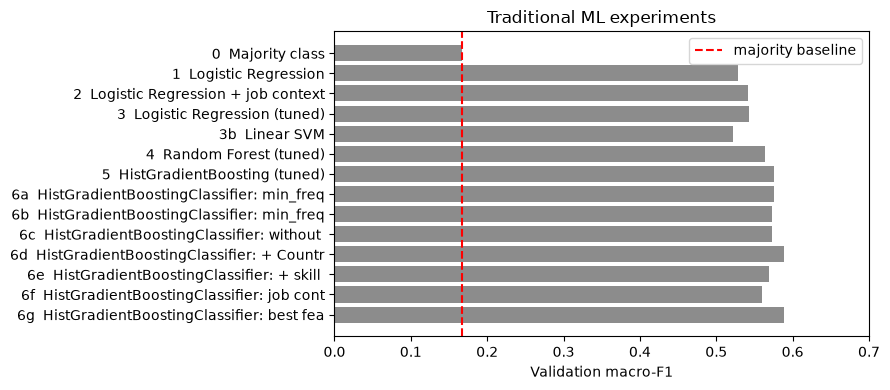

In [24]:
classic = show(0, 1, 2, 3, "3b", 4, 5, *ABLATIONS, "6g")
display(classic.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(classic.index[::-1] + "  " + classic["model"][::-1].str.slice(0, 40),
        classic["val_macro_f1"][::-1], color="#8C8C8C")
ax.axvline(classic.loc["0", "val_macro_f1"], color="red", ls="--", label="majority baseline")
ax.set(xlabel="Validation macro-F1", title="Traditional ML experiments", xlim=(0, 0.7))
ax.legend(); plt.tight_layout(); plt.savefig(f"{FIG}/classic_experiments.png", dpi=200); plt.show()

**Interpretation.** Validation macro-F1 climbs in clear steps: chance 0.167 → linear models 0.52-0.54 → random forest 0.563 → gradient boosting 0.576 → gradient boosting with the best features **0.589**. The biggest jumps come from (1) any model at all, (2) going **non-linear** and (3) adding **job context and Country** as features. Tuning regularisation (exp 3) and fine feature thresholds (6a/6b) barely matter. A ceiling near 0.59 is reasonable for predicting pay from a survey that has no information on employer, city, negotiation or performance.

## 10. Deep learning with TensorFlow / Keras (experiments 7-9)

**Input pipeline (`tf.data`).** The scikit-learn preprocessor is fitted on the **training rows only** and turns each table into a numeric matrix. `make_dataset` in `src/dl.py` then builds the Keras input pipeline:

1. `tf.data.Dataset.from_tensor_slices((X, y))`: one element per respondent,
2. `.shuffle(buffer, seed=42)`: a new random order each epoch (training only), reproducible because of the seed,
3. `.batch(batch_size)`: groups rows for each gradient step,
4. `.prefetch(tf.data.AUTOTUNE)`: prepares the next batch while the current one trains.

**Training setup (all Keras runs).** Softmax output with 3 units, `sparse_categorical_crossentropy` loss, Adam optimiser, **early stopping on validation loss** (training stops when validation loss has not improved for `patience` epochs and the best weights are restored). Determinism: `set_random_seed(42)` + `enable_op_determinism()`, so a rerun gives identical weights. Each run logs to TensorBoard (`logs/keras/<run_id>`).

**Note.** Early stopping looks at the validation loss, so the validation score of a Keras model is slightly optimistic. This is one reason the final comparison is done on the untouched test set.

**Features.** The Keras models use the same feature set as the final traditional model (exp 6g), so the comparison is about the **model**, not the inputs.

In [25]:
import tensorflow as tf
from src.dl import KerasPipeline, KerasTracker, make_dataset
from src.pipeline import JOB_CONTEXT

ktracker = KerasTracker(train, val, target=TARGET, seed=SEED)
DL_PRE = dict(best_features)
print("TensorFlow", tf.__version__, "| feature settings:", DL_PRE)

# What tf.data produces: one look at the first training batch
pre_dl = build_preprocessor(**DL_PRE).fit(train)
X_demo = pre_dl.transform(train).astype("float32")
y_demo = y_train.map({"Low": 0, "Mid": 1, "High": 2}).to_numpy()
ds = make_dataset(X_demo, y_demo, batch_size=256, shuffle=True, seed=SEED)
print(ds.element_spec)
xb, yb = next(iter(ds))
print("One batch:", xb.shape, yb.shape, "| batches per epoch:", len(ds))

TensorFlow 2.22.0-rc0 | feature settings: {'use_job_context': True, 'use_country': True}


(TensorSpec(shape=(None, 284), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))
One batch: (256, 284) (256,) | batches per epoch: 196


### Experiment 7: Sequential MLP

**Model.** `tf.keras.Sequential`: input (all preprocessed features) → Dense 256 (ReLU) → Dropout 0.3 → Dense 128 (ReLU) → Dropout 0.3 → Dense 3 (softmax).

**Why these settings.** Two hidden layers is a standard starting point for a few hundred tabular inputs; dropout 0.3 limits overfitting; Adam with learning rate 0.001 and batch 256 are common defaults that we tune in exp 9. Up to 100 epochs with early stopping (patience 8).

**Hypothesis.** The MLP can model interactions like the tree models, so it should beat logistic regression. On tabular data of this size, gradient boosting usually stays slightly ahead.

[exp 7] hashes match -> loading saved model, no refit


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        72,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 318,731 (1.22 MB)

 Trainable params: 106,243 (415.01 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 212,488 (830.04 KB)

Epochs trained: 14


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds,epochs_trained
id,,,,,,,,,,,,
7,Keras Sequential MLP,0.5903,0.5932,0.7801,0.6614,0.6641,0.4595,0.0498,0.7233,0.4618,25.5,14.0


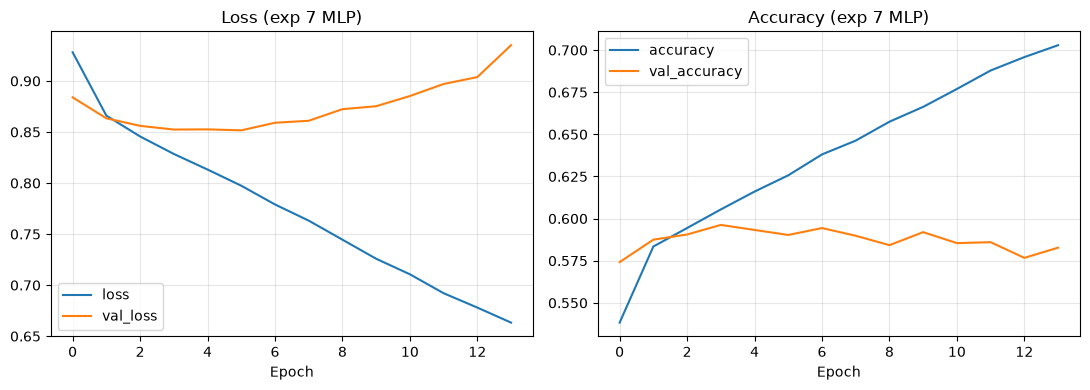

In [26]:
mlp = ktracker.run(7, "Keras Sequential MLP",
    KerasPipeline(kind="mlp", pre_kwargs=DL_PRE, hidden=(256, 128), dropout=0.3,
                  lr=1e-3, batch_size=256, epochs=100, patience=8, seed=SEED),
    settings={"arch": "Dense256-Drop0.3-Dense128-Drop0.3-Softmax3", "lr": 1e-3,
              "batch": 256, "early_stopping": "val_loss, patience 8"},
    note="first deep model")
mlp.model_.summary()
print("Epochs trained:", len(mlp.history_["loss"]))
show_k = lambda *ids: ktracker.table().assign(id=lambda t: t["id"].astype(str)).set_index("id").loc[[str(i) for i in ids], COLS + ["epochs_trained"]]
display(show_k(7))
from src.evaluation import plot_history
plot_history(mlp.history_, "(exp 7 MLP)", name="exp7_history.png"); plt.show()

**Observation.** - The MLP has **106,243 trainable weights** and stopped after **14 epochs** (best weights restored from epoch 6, patience 8).
- Validation macro-F1 **0.593**, accuracy 0.590, AUC **0.780**: already **slightly above the best gradient-boosting model (0.589)**, with the fewest far errors so far (0.050) and a clearly better youth macro-F1 (**0.462** vs 0.389).
- Train accuracy 0.661 vs validation 0.590: a 7-point gap. The loss curves show validation loss reaching its minimum after a few epochs and then rising while training loss keeps falling. That is **overfitting after the early epochs**, which early stopping catches.

### Experiment 8: Functional model with embeddings

**What changes vs. exp 7 (architecture).** The Keras **Functional API** allows several inputs. Categorical columns are no longer one-hot encoded; each one gets its own input and a small **embedding** (a learned dense vector per category, size ≤ 8). The numeric + multi-hot block goes through its own Dense 256 branch. The branches are concatenated, then Dense 128 → softmax.

**Categoricals used.** `OrgSize`, `RemoteWork`, `ICorPM`, `Industry` and `Country`: the same information exp 7 receives as one-hot columns, now as embeddings.

**Hypothesis.** Embeddings let the model learn which categories behave alike (e.g. similar company sizes), which can help a little. With only a few short categorical columns, the gain over one-hot encoding is likely small.

Embedded columns: ['OrgSize', 'RemoteWork', 'ICorPM', 'Industry', 'Country']
[exp 8] hashes match -> loading saved model, no refit


Epochs trained: 16


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds,epochs_trained
id,,,,,,,,,,,,
7,Keras Sequential MLP,0.5903,0.5932,0.7801,0.6614,0.6641,0.4595,0.0498,0.7233,0.4618,25.5,14.0
8,Keras Functional (embeddings),0.5946,0.5934,0.7789,0.6565,0.6556,0.4618,0.0564,0.7216,0.4360,28.7,16.0


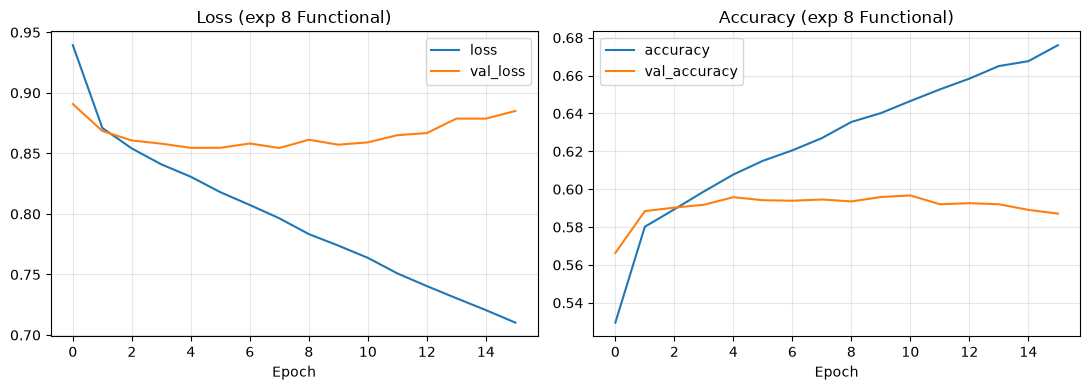

In [27]:
cat_cols = list(JOB_CONTEXT if DL_PRE.get("use_job_context") else []) + \
           (["Country"] if DL_PRE.get("use_country") else [])
if not cat_cols:
    cat_cols = list(JOB_CONTEXT)  # the architecture needs categoricals to embed
pre_kw8 = {**DL_PRE, "use_job_context": False, "use_country": False}  # categoricals go to embeddings
print("Embedded columns:", cat_cols)

func = ktracker.run(8, "Keras Functional (embeddings)",
    KerasPipeline(kind="functional", cat_cols=cat_cols, pre_kwargs=pre_kw8,
                  hidden=(256, 128), dropout=0.3, lr=1e-3, batch_size=256,
                  epochs=100, patience=8, seed=SEED),
    settings={"arch": "dense branch 256 + embeddings -> concat -> 128 -> softmax",
              "embedded": cat_cols, "lr": 1e-3, "batch": 256},
    note="architecture change")
print("Epochs trained:", len(func.history_["loss"]))
display(show_k(7, 8))
plot_history(func.history_, "(exp 8 Functional)", name="exp8_history.png"); plt.show()

**Observation.** - Validation macro-F1 **0.593** (same as exp 7), accuracy 0.595 (+0.4 points), 16 epochs. Youth macro-F1 is lower (0.436 vs 0.462) and far errors slightly higher (0.056 vs 0.050).
- Embeddings neither clearly help nor hurt. With only five short categorical columns, one-hot encoding already represents them well, as expected. The architecture is a fair alternative, not an improvement. Exp 8 had a marginally higher macro-F1 (0.5934 vs 0.5932), so the code tunes it next.

### Experiment 9: optimisation of the better architecture

**What changes vs. exp 7/8.** The architecture with the higher validation macro-F1 is kept, and we tune the **optimisation**: learning rate (0.001 vs 0.0003), batch size (256 vs 1024) and L2 weight penalty (0 vs 0.0001), 8 combinations (9a-9h). All runs add **ReduceLROnPlateau** (halve the learning rate when validation loss stalls for 2 epochs) on top of early stopping.

**Hypothesis.** A smaller learning rate with learning-rate decay converges to a slightly better minimum; larger batches train faster per epoch but may generalise slightly worse; L2 adds regularisation that matters only if the model overfits (see the exp 7/8 loss curves).

In [28]:
best_arch = show_k(7, 8)["val_macro_f1"].idxmax()
arch_kw = (dict(kind="mlp", pre_kwargs=DL_PRE) if best_arch == "7"
           else dict(kind="functional", cat_cols=cat_cols, pre_kwargs=pre_kw8))
print("Tuning architecture from exp", best_arch)

grid = [(lr, bs, l2) for lr in (1e-3, 3e-4) for bs in (256, 1024) for l2 in (0.0, 1e-4)]
dl_runs = {}
for letter, (lr, bs, l2) in zip("abcdefgh", grid):
    dl_runs[f"9{letter}"] = ktracker.run(f"9{letter}", f"Keras tuned (from exp {best_arch})",
        KerasPipeline(**arch_kw, hidden=(256, 128), dropout=0.3, l2=l2, lr=lr,
                      batch_size=bs, epochs=150, patience=10, reduce_lr=True, seed=SEED),
        settings={"from": f"exp {best_arch}", "lr": lr, "batch": bs, "l2": l2,
                  "reduce_lr": "x0.5 after 2 stalled epochs", "patience": 10},
        note="optimisation grid")
show_k(best_arch, *dl_runs)

Tuning architecture from exp 8
[exp 9a] hashes match -> loading saved model, no refit


[exp 9b] hashes match -> loading saved model, no refit


[exp 9c] hashes match -> loading saved model, no refit


[exp 9d] hashes match -> loading saved model, no refit


[exp 9e] hashes match -> loading saved model, no refit


[exp 9f] hashes match -> loading saved model, no refit


[exp 9g] hashes match -> loading saved model, no refit


[exp 9h] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds,epochs_trained
id,,,,,,,,,,,,
8,Keras Functional (embeddings),0.5946,0.5934,0.7789,0.6565,0.6556,0.4618,0.0564,0.7216,0.4360,28.7,16.0
9a,Keras tuned (from exp 8),0.5927,0.5922,0.7794,0.6574,0.6574,0.4643,0.0571,0.7224,0.4544,33.3,18.0
9b,Keras tuned (from exp 8),0.5943,0.5961,0.7795,0.6345,0.6365,0.4575,0.0518,0.7199,0.4149,30.5,16.0
9c,Keras tuned (from exp 8),0.5940,0.5928,0.7783,0.6444,0.6435,0.4640,0.0580,0.7182,0.4225,30.3,21.0
9d,Keras tuned (from exp 8),0.5976,0.5969,0.7795,0.6416,0.6414,0.4590,0.0566,0.7233,0.4419,29.9,21.0
9e,Keras tuned (from exp 8),0.5945,0.5915,0.7778,0.6349,0.6323,0.4664,0.0609,0.7292,0.4685,38.2,24.0
9f,Keras tuned (from exp 8),0.5974,0.5950,0.7795,0.6484,0.6465,0.4643,0.0616,0.7284,0.4623,44.6,29.0
9g,Keras tuned (from exp 8),0.5964,0.5945,0.7771,0.6349,0.6334,0.4617,0.0582,0.7301,0.4652,50.8,43.0
9h,Keras tuned (from exp 8),0.5973,0.5961,0.7786,0.6440,0.6429,0.4614,0.0586,0.7301,0.4617,51.7,44.0


Best Keras model: exp 9d | epochs: 21


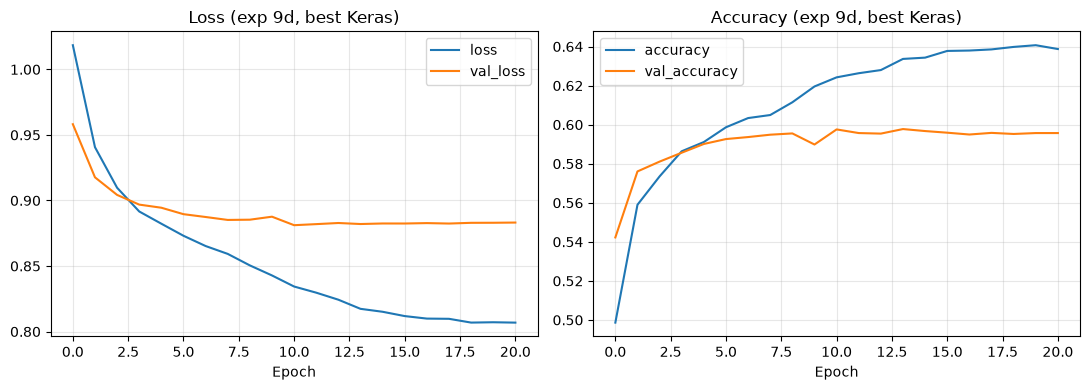

In [29]:
best_dl_id = show_k(7, 8, *dl_runs)["val_macro_f1"].idxmax()
best_dl = {"7": mlp, "8": func, **dl_runs}[best_dl_id]
print("Best Keras model: exp", best_dl_id, "| epochs:", len(best_dl.history_["loss"]))
plot_history(best_dl.history_, f"(exp {best_dl_id}, best Keras)", name="best_keras_history.png"); plt.show()

**Observation.** - All eight settings land between macro-F1 **0.592 and 0.597**; the best is **9d** (learning rate 0.001, batch 1024, L2 0.0001): macro-F1 **0.597**, accuracy 0.598, AUC 0.780, 21 epochs.
- A spread of 0.005 is about the size of run-to-run noise on 10,742 validation rows. The honest conclusion is that **the optimiser settings barely matter** once early stopping and learning-rate decay are in place.
- Patterns: the smaller learning rate (0.0003, runs 9e-9h) needs 24-44 epochs instead of 16-21 for the same result. Batch 1024 is slightly better here than 256. The best youth scores come from the low-learning-rate runs (youth macro-F1 up to 0.469).
- The validation set chose the epoch (early stopping) **and** the setting, so 0.597 is optimistic; the test set will give the fair number.
- In the best run, ReduceLROnPlateau halved the learning rate several times (to 0.00003 by the end), and validation loss levelled off instead of rising as it did in exp 7.

## 11. Population, label and ordinal experiments (10-12)

These experiments ask questions about the **mission**, not just about model accuracy. They reuse the final traditional pipeline (exp 6g: same model, hyperparameters and features), so any change comes from the data or the label.

### Experiment 10: broader training population

**What changes vs. exp 6g.** Training rows are added from people the strict filter removed: those who "code sometimes" for work or study, and part-time / freelance workers. Many young people start in these situations.

**How they are labelled (no leakage).** Their tier is assigned with the **per-country salary cut-offs of the strict training set** (`label_with_cutoffs`), so "Low/Mid/High" means the same salary range as in the main data. Only countries present in the training set are used.

**Evaluation.** On the **same strict validation set** as every other experiment, so the scores are directly comparable.

**Hypothesis.** More early-career examples could help the youth subgroup. But the added people differ (part-time pay is lower for reasons unrelated to skill), so they may also add noise.

In [30]:
from src.preprocessing import (filter_respondents, label_with_cutoffs, add_experience_label,
                               PRO_DEV, CODE_SOMETIMES)

def row_key(d):
    return d["Year"].astype(str) + "_" + d["ResponseId"].astype(str)

broad, _ = filter_respondents(df, branches=(PRO_DEV, CODE_SOMETIMES), full_time_only=False)
extra = broad[~row_key(broad).isin(row_key(data))]      # people outside the strict population
extra = add_basic_features(label_with_cutoffs(extra, train))
train_broad = pd.concat([train, extra], ignore_index=True)

print("Extra training rows:", len(extra), "| youth among them:", int(extra["IsYouth"].sum()))
print(extra["MainBranch"].str.slice(0, 45).value_counts(), "\n")
print("Extra rows' tier mix:\n", extra["PayTier"].value_counts(normalize=True).round(3))

Extra training rows: 17159 | youth among them: 2022
MainBranch
I am a developer by profession                   9830
I am not primarily a developer, but I write c    7329
Name: count, dtype: int64 

Extra rows' tier mix:
 PayTier
Low     0.409
High    0.368
Mid     0.223
Name: proportion, dtype: float64


In [31]:
broad_model = tracker.run(10, f"{TreeClass.__name__}: broader training population",
    tree_pipe(**best_features),
    settings={"base": "exp 6g", "train": "strict train + code-sometimes + part-time/freelance",
              "extra_rows": len(extra), "labels": "strict train per-country cut-offs"},
    note="evaluated on the same strict validation set", train=train_broad)
display(show("6g", 10))
pd.concat({"exp 6g": subgroup_table(sk_final, val, y_val, val["IsYouth"]),
           "exp 10": subgroup_table(broad_model, val, y_val, val["IsYouth"])}, axis=1)

[exp 10] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
6g,HistGradientBoostingClassifier: best feature set,0.5929,0.5885,0.7765,0.6323,0.6289,0.4676,0.0605,0.7241,0.3894,64.9
10,HistGradientBoostingClassifier: broader traini...,0.5922,0.5829,0.7770,0.6263,0.6090,0.4767,0.0689,0.7182,0.3598,62.0


exp 6g                                                        exp 10                                                       
           n accuracy macro_f1 majority_class majority_baseline_acc      n accuracy macro_f1 majority_class majority_baseline_acc
group                                                                                                                            
False   9564    0.577    0.574           High                 0.367   9564    0.577     0.57           High                 0.367
True    1178    0.724    0.389            Low                 0.711   1178    0.718     0.36            Low                 0.711

**Observation.** - 17,159 extra training rows (9,830 part-time/freelance professionals + 7,329 who code sometimes), 2,022 of them young. Their tier mix is 41% Low / 22% Mid / 37% High against the strict cut-offs: they are more spread out than full-time developers.
- Result on the same strict validation set: macro-F1 **0.583 vs 0.589**, and **youth macro-F1 falls from 0.389 to 0.360**.
- The hypothesis is **not supported**. The added people are paid differently for reasons the features cannot see (hours, contract type, non-developer jobs), so they add noise rather than useful early-career signal. Keep the strict population for the final model.

### Experiment 11: experience-adjusted label

**What changes.** A **new target**, `PayTierExp`: salary terciles within **country × years-of-coding band** (0-4, 5-9, 10-19, 20+ years). A "High" now means "paid well *for someone with your experience in your country*". Groups with fewer than 30 people, and rows with unknown experience, are left out.

**Why.** With the main label, most young people are "Low" simply because they are junior (see section 12). This label removes most of the seniority effect and asks the mission question directly: **do skills and choices still separate pay once experience is held roughly constant?**

**Important.** This is a different, harder task (the strongest predictor, experience, is mostly removed), so its scores are **not on the same scale** as experiments 0-10 and are reported separately. The same split membership (train/validation rows) is kept.

In [32]:
data_exp = add_experience_label(data)
exp_label = pd.Series(data_exp["PayTierExp"].values, index=row_key(data_exp))

def with_exp_label(d):
    out = d.assign(PayTierExp=row_key(d).map(exp_label).values)
    return out[out["PayTierExp"].notna()].reset_index(drop=True)

train11, val11 = with_exp_label(train), with_exp_label(val)
print("Rows with the new label: train", len(train11), "| val", len(val11))
print("\nYouth tier mix, main label vs experience-adjusted (train):")
print(pd.DataFrame({"PayTier": train11.loc[train11["IsYouth"], "PayTier"].value_counts(normalize=True),
                    "PayTierExp": train11.loc[train11["IsYouth"], "PayTierExp"].value_counts(normalize=True)}).round(3))

tracker11 = ExperimentTracker(train11, val11, target="PayTierExp", seed=SEED)
tracker11.run("11a", "Majority class (experience-adjusted label)",
    Pipeline([("pre", build_preprocessor()), ("clf", DummyClassifier(strategy="most_frequent"))]),
    settings={"label": "tercile within Country x YearsCode band"}, note="different label: separate scale")
exp_model = tracker11.run(11, f"{TreeClass.__name__}: experience-adjusted label", tree_pipe(**best_features),
    settings={"label": "tercile within Country x YearsCode band", "params": tree_params},
    note="different label: separate scale")
t11 = tracker11.table().assign(id=lambda t: t["id"].astype(str)).set_index("id")
t11.loc[["11a", "11"], COLS]

Rows with the new label: train 49389 | val 10609

Youth tier mix, main label vs experience-adjusted (train):
      PayTier  PayTierExp
Low     0.715        0.54
Mid     0.205        0.29
High    0.080        0.17
[exp 11a] hashes match -> loading saved model, no refit


[exp 11] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
11a,Majority class (experience-adjusted label),0.3340,0.1669,0.50,0.3344,0.1671,0.9973,0.3312,0.1620,0.0930,3.2
11,HistGradientBoostingClassifier: experience-adj...,0.5427,0.5357,0.73,0.5891,0.5835,0.5441,0.0867,0.5845,0.4513,49.0


**Observation.** - 49,389 training and 10,609 validation rows keep the new label (the rest have unknown experience or fall in a group under 30 people).
- The youth tier mix becomes much more even: **Low 54% / Mid 29% / High 17%** with the experience-adjusted label, against 71.5% / 20.5% / 8.0% with the main label. Much of "young = Low" is indeed seniority.
- The model reaches macro-F1 **0.536** against a majority baseline of **0.167** (AUC 0.730). **Profile and skills still separate pay within an experience band**, which is the main finding for the mission. Youth macro-F1 rises to **0.451** (vs 0.389 on the main label).
- Experience still ranks high in section 12.5. The bands are wide (10-19 years is one band) and `WorkExp` differs from `YearsCode`, so some seniority remains inside each band.

### Experiment 12: ordinal model for the ordered tiers

**What changes vs. exp 6g.** The classifier knows that Low < Mid < High. Following Frank & Hall's approach, two binary models are trained with the same tuned tree settings: "is the tier above Low?" and "is it above Mid?". Their probabilities combine into P(Low) = 1 − P(>Low), P(Mid) = P(>Low) − P(>Mid), P(High) = P(>Mid).

**Hypothesis.** Experiment 1 showed that Mid is the hardest tier, because its errors split to both neighbours. Using the order should reduce far errors (Low↔High) and may raise Mid recall.

In [33]:
from sklearn.base import clone
from sklearn.metrics import classification_report
from src.models import OrdinalClassifier
from src.evaluation import TIER_ORDER

ordinal = tracker.run(12, f"Ordinal {TreeClass.__name__}",
    Pipeline([("pre", build_preprocessor(**best_features)),
              ("clf", OrdinalClassifier(TreeClass(random_state=SEED, **base_kwargs, **tree_params)))]),
    settings={"base": "exp 6g", "method": "Frank & Hall cumulative binary models"},
    note="uses the order Low < Mid < High")
display(show("6g", 12))
for name, m in [("exp 6g (flat)", sk_final), ("exp 12 (ordinal)", ordinal)]:
    print(name); print(classification_report(y_val, m.predict(val), labels=TIER_ORDER, digits=3))

[exp 12] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
6g,HistGradientBoostingClassifier: best feature set,0.5929,0.5885,0.7765,0.6323,0.6289,0.4676,0.0605,0.7241,0.3894,64.9
12,Ordinal HistGradientBoostingClassifier,0.5858,0.5831,0.7728,0.6171,0.6149,0.4717,0.0575,0.7224,0.3905,37.9


exp 6g (flat)


              precision    recall  f1-score   support

         Low      0.656     0.675     0.665      3578
         Mid      0.477     0.418     0.446      3580
        High      0.626     0.686     0.655      3584

    accuracy                          0.593     10742
   macro avg      0.586     0.593     0.589     10742
weighted avg      0.586     0.593     0.589     10742

exp 12 (ordinal)


              precision    recall  f1-score   support

         Low      0.659     0.660     0.659      3578
         Mid      0.462     0.425     0.443      3580
        High      0.624     0.673     0.647      3584

    accuracy                          0.586     10742
   macro avg      0.581     0.586     0.583     10742
weighted avg      0.581     0.586     0.583     10742



**Observation.** - The ordinal model **does not beat the flat model**: macro-F1 0.583 vs 0.589. It does make **fewer far errors** (5.75% vs 6.05% Low↔High).
- Mid recall moves only from 0.418 to 0.425; Low and High recall drop a little. Using the order nudges errors toward neighbouring tiers but does not solve Mid.
- Interpretation: Mid is hard because its salaries sit between two neighbours with very similar profiles, not because the model ignores the order. The flat exp 6g stays the traditional candidate.

## 11b. Improvement round (experiments 13-15)

After experiments 0-12, three improvements remained that the results themselves pointed to. Each builds on the previous one and is still judged on the validation set only.

| Exp | Change | Evidence that motivated it |
|---|---|---|
| 13 | Gradient boosting with up to 2,000 rounds (early stopping still on) | exp 5 used all 500 rounds; it had not finished learning |
| 14 | Three unused survey columns | `PurchaseInfluence` is almost complete in every year and plausibly linked to seniority/responsibility |
| 15 | Soft-voting ensemble of the best tree and best Keras model | the two make different errors (Keras better on Mid and youth, trees on Low/High) |

### Experiment 13: more boosting rounds

**What changes vs. exp 6g.** Only `max_iter`: 500 → 2,000. Early stopping (20 rounds without improvement on an internal 10% split of the training rows) decides when to stop, so this cannot overfit by brute force.

**Hypothesis.** A small gain, since the learning rate is low (≈0.025) and exp 5 stopped at the cap.

In [34]:
def tree_pipe_long(**pre_kwargs):
    # Same tuned HGB as 6g but with up to 2,000 boosting rounds
    pre_kwargs = {"use_job_context": best_lr_ctx, **pre_kwargs}
    return Pipeline([("pre", build_preprocessor(**pre_kwargs)),
                     ("clf", HistGradientBoostingClassifier(
                         max_iter=2000, early_stopping=True, n_iter_no_change=20,
                         random_state=SEED, **tree_params))])

hgb_long = tracker.run(13, "HGB best features, up to 2000 rounds", tree_pipe_long(**best_features),
    settings={"base": "exp 6g", "max_iter": 2000, "params": tree_params},
    note="exp 5 hit the 500-round cap")
print("Boosting rounds used:", hgb_long.named_steps["clf"].n_iter_)
show("6g", 13)

[exp 13] hashes match -> loading saved model, no refit


Boosting rounds used: 820


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
6g,HistGradientBoostingClassifier: best feature set,0.5929,0.5885,0.7765,0.6323,0.6289,0.4676,0.0605,0.7241,0.3894,64.9
13,"HGB best features, up to 2000 rounds",0.5970,0.5932,0.7792,0.6520,0.6491,0.4616,0.0586,0.7233,0.3961,77.3


**Observation.** - With the cap raised, early stopping ended training at **820 rounds** (out of 2,000), so 500 was indeed too few.
- Validation macro-F1 0.589 → **0.593**, accuracy 0.597, AUC 0.779; youth macro-F1 0.389 → 0.396. A small but free gain.
- Train macro-F1 rises to 0.649, so the train-validation gap grows a little (to about 0.056); early stopping keeps it in check.

### Experiment 14: three unused survey columns

**What changes vs. exp 13.** Three columns that were dropped so far are added:
- `PurchaseInfluence_ord`: influence over technology purchases, as a number 0-2. **The survey changed this question's wording in 2025**, so the raw answers cannot be one-hot encoded: the categories would identify the year. `add_basic_features` maps both versions onto one scale: 0 = none ("little or no influence" / "No"), 1 = some ("some influence" / "Yes, I endorsed or influenced a smaller tool"), 2 = major ("a great deal of influence" / "Yes, … a substantial addition to the tech stack"). The mapping is our judgement and is printed below so it can be checked.
- `OfficeStackAsyncHaveWorkedWith` (collaboration tools such as Jira or Confluence) and `OpSysProfessional use` (operating systems used at work), multi-hot like the other skills. Their answer options are the same in all three years.

**Hypothesis.** Purchase influence is a responsibility signal and should help; the tool columns may add a little. The gain must hold **in every year**, or it may be a year proxy.

In [35]:
print("PurchaseInfluence mapping (training rows):")
display(train.groupby(["Year", "PurchaseInfluence"]).size().rename("rows").reset_index()
        .assign(mapped=lambda d: d["PurchaseInfluence"].map(
            dict(zip(train["PurchaseInfluence"], train["PurchaseInfluence_ord"])))))
print(pd.crosstab(train["PurchaseInfluence_ord"], train[TARGET], normalize="index").round(2))

feat14 = {**best_features, "extra_features": True}
hgb_extra = tracker.run(14, "HGB + PurchaseInfluence, office tools, work OS", tree_pipe_long(**feat14),
    settings={"base": "exp 13", "added": "PurchaseInfluence_ord, OfficeStackAsyncHaveWorkedWith, OpSysProfessional use",
              "params": tree_params},
    note="new columns, harmonised across years")
display(show(13, 14))
pd.DataFrame({"exp 13": accuracy_by_group(hgb_long, val, y_val, val["Year"]),
              "exp 14": accuracy_by_group(hgb_extra, val, y_val, val["Year"])})

PurchaseInfluence mapping (training rows):


,Year,PurchaseInfluence,rows,mapped
0,2023,I have a great deal of influence,5063,2.0
1,2023,I have little or no influence,9873,0.0
2,2023,I have some influence,11542,1.0
3,2024,I have a great deal of influence,2212,2.0
4,2024,I have little or no influence,4884,0.0
5,2024,I have some influence,5292,1.0
6,2025,No,5982,0.0
7,2025,"Yes, I endorsed a tool that was open-source an...",1803,1.0
8,2025,"Yes, I endorsed a tool that was ultimately not...",395,1.0
9,2025,"Yes, I influenced the purchase of a substantia...",2020,2.0


PayTier                 Low   Mid  High
PurchaseInfluence_ord                  
0.0                    0.37  0.33  0.30
1.0                    0.33  0.34  0.33
2.0                    0.27  0.31  0.42
[exp 14] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
13,"HGB best features, up to 2000 rounds",0.5970,0.5932,0.7792,0.6520,0.6491,0.4616,0.0586,0.7233,0.3961,77.3
14,"HGB + PurchaseInfluence, office tools, work OS",0.6088,0.6064,0.7887,0.6694,0.6672,0.4437,0.0525,0.7368,0.4614,93.0


,exp 13,exp 14
2023,0.586,0.605
2024,0.601,0.608
2025,0.617,0.619


**Observation.** - The mapping table shows both wordings landing on the same 0/1/2 scale. The High share rises from 30% at level 0 to 42% at level 2, which is the expected direction.
- Validation macro-F1 0.593 → **0.606**, accuracy **0.609**, AUC **0.789**, far errors down to 5.3%, and youth macro-F1 up to **0.461**. This is the largest single gain since adding Country.
- **By year:** +1.9 points in 2023, +0.7 in 2024, +0.2 in 2025. The gain holds in all three years but is uneven, so experiment 14b checks it for leakage.

### Experiment 14b: leakage probe and the office-tools ablation

**Why.** The gain in exp 14 is largest in 2023, so we test whether a new column could be acting as a hidden **survey-year flag**. Probe: a logistic regression tries to predict the **survey year** from one column alone. Chance is the share of the most common year. A column that predicts the year well could let the model learn year drift instead of pay.

Then **14b** removes the most year-informative new column from exp 14, keeping everything else fixed, to measure what it actually contributes.

In [36]:
from src.transformers import MultiHotEncoder

def year_probe(col):
    # Validation accuracy of predicting the survey year from one multi-select column
    enc = MultiHotEncoder().fit(train[[col]])
    m = LogisticRegression(max_iter=2000).fit(enc.transform(train[[col]]), train["Year"])
    return (m.predict(enc.transform(val[[col]])) == val["Year"]).mean()

probe_cols = ["LanguageHaveWorkedWith", "PlatformHaveWorkedWith", "OpSysProfessional use",
              "OfficeStackAsyncHaveWorkedWith"]
probe = pd.Series({c: year_probe(c) for c in probe_cols}, name="year-probe accuracy").round(3)
print("Chance (most common year):", round(val["Year"].value_counts(normalize=True).max(), 3))
display(probe.to_frame().assign(new_in_exp14=[False, False, True, True]))

Chance (most common year): 0.529


,year-probe accuracy,new_in_exp14
LanguageHaveWorkedWith,0.531,False
PlatformHaveWorkedWith,0.702,False
OpSysProfessional use,0.560,True
OfficeStackAsyncHaveWorkedWith,0.739,True


In [37]:
def without_columns(pipe, drop):
    # Same pipeline with some multi-select columns removed from the multi-hot step
    pre = pipe.named_steps["pre"]
    pre.transformers = [(n, t, [c for c in cols if c not in drop]) if n == "multi" else (n, t, cols)
                        for n, t, cols in pre.transformers]
    return pipe

hgb_14b = tracker.run("14b", "HGB exp 14 without office tools",
    without_columns(tree_pipe_long(**feat14), ["OfficeStackAsyncHaveWorkedWith"]),
    settings={"base": "exp 14", "removed": "OfficeStackAsyncHaveWorkedWith", "params": tree_params},
    note="ablation: most year-informative new column")
display(show(13, 14, "14b"))
pd.DataFrame({"exp 13": accuracy_by_group(hgb_long, val, y_val, val["Year"]),
              "exp 14": accuracy_by_group(hgb_extra, val, y_val, val["Year"]),
              "exp 14b": accuracy_by_group(hgb_14b, val, y_val, val["Year"])})

[exp 14b] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
13,"HGB best features, up to 2000 rounds",0.5970,0.5932,0.7792,0.6520,0.6491,0.4616,0.0586,0.7233,0.3961,77.3
14,"HGB + PurchaseInfluence, office tools, work OS",0.6088,0.6064,0.7887,0.6694,0.6672,0.4437,0.0525,0.7368,0.4614,93.0
14b,HGB exp 14 without office tools,0.5998,0.5967,0.7844,0.6594,0.6571,0.4556,0.0554,0.7343,0.4500,163.3


,exp 13,exp 14,exp 14b
2023,0.586,0.605,0.592
2024,0.601,0.608,0.604
2025,0.617,0.619,0.615


**Observation.** - **Year probe** (chance 0.529): `OpSysProfessional use` predicts the year at only 0.560, close to languages (0.531), so it carries almost no year information. `OfficeStackAsyncHaveWorkedWith` reaches **0.739**, about as year-informative as the platforms column (0.702) that the model has used since experiment 1.
- **14b (office tools removed):** macro-F1 0.606 → **0.597**. The office tools are worth about **0.010**, mostly in 2023 (accuracy 0.605 with them, 0.592 without).
- **Is it a year flag?** A year flag would help most where the tier mix drifts, which is **2025**. The office-tools gain in 2025 is only +0.4 points. Tools such as Jira and Confluence plausibly mark larger, more corporate employers, a real pay signal. We keep exp 14 and state the probe result as a limitation.
- Permutation importance on exp 14: OS at work 0.024, office tools 0.013, purchase influence 0.007 (for scale: years coding 0.053).

### Experiment 15: ensemble of the best tree and the best Keras model

**What changes.** No new training for the tree model. The probabilities of the best gradient-boosting model and the best Keras model are **averaged with equal weights** (soft voting), and the tier with the highest average wins. If experiment 14's columns helped, the Keras model is first retrained (15a) on the same features with the exp 9d settings, so both members see the same inputs.

**Why equal weights.** Tuning the weights on the validation set would fit the validation set; equal weights are a fixed, honest choice.

**Hypothesis.** The two model families make different errors, so averaging should beat both members by a small margin.

In [38]:
import json
from src.models import SavedModelEnsemble

best_tree_final = show("6g", 13, 14)["val_macro_f1"].idxmax()
use_extra = best_tree_final == "14"
best_keras_final = best_dl_id
if use_extra:
    p9d = {"lr": 1e-3, "batch_size": 1024, "l2": 1e-4}
    keras_extra = ktracker.run("15a", "Keras tuned (9d settings) + new columns",
        KerasPipeline(kind="functional", cat_cols=cat_cols, pre_kwargs={**pre_kw8, "extra_features": True},
                      hidden=(256, 128), dropout=0.3, l2=p9d["l2"], lr=p9d["lr"],
                      batch_size=p9d["batch_size"], epochs=150, patience=10, reduce_lr=True, seed=SEED),
        settings={"from": "exp 9d", "added": "exp 14 columns"}, note="Keras on the exp 14 features")
    display(show_k(best_dl_id, "15a"))
    best_keras_final = show_k(best_dl_id, "15a")["val_macro_f1"].idxmax()

def member_run_id(exp_id):
    return json.loads((tracker.settings_dir / f"exp_{exp_id}.json").read_text())["run_id"]

members = (("sklearn", best_tree_final), ("keras", best_keras_final))
ensemble = tracker.run(15, f"Ensemble: exp {best_tree_final} + exp {best_keras_final}",
    SavedModelEnsemble(members=members, weights=(1, 1)),
    settings={"members": [f"{k} exp {i} ({member_run_id(i)})" for k, i in members], "weights": "equal"},
    note="soft voting, no refit")
show(best_tree_final, best_keras_final, 15)

[exp 15a] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds,epochs_trained
id,,,,,,,,,,,,
9d,Keras tuned (from exp 8),0.5976,0.5969,0.7795,0.6416,0.6414,0.4590,0.0566,0.7233,0.4419,29.9,21.0
15a,Keras tuned (9d settings) + new columns,0.6031,0.6025,0.7861,0.6664,0.6663,0.4494,0.0524,0.7233,0.4775,32.3,21.0


[exp 15] hashes match -> loading saved model, no refit


,model,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_accuracy,train_macro_f1,val_mean_tier_error,val_far_error_rate,val_youth_accuracy,val_youth_macro_f1,fit_seconds
id,,,,,,,,,,,
14,"HGB + PurchaseInfluence, office tools, work OS",0.6088,0.6064,0.7887,0.6694,0.6672,0.4437,0.0525,0.7368,0.4614,93.0
15a,Keras tuned (9d settings) + new columns,0.6031,0.6025,0.7861,0.6664,0.6663,0.4494,0.0524,0.7233,0.4775,32.3
15,Ensemble: exp 14 + exp 15a,0.6108,0.6090,0.7926,0.6761,0.6749,0.4398,0.0505,0.7360,0.4757,0.6


**Observation.** - **15a:** the Keras model with the exp 9d settings, retrained on the exp 14 features, improves from 0.597 to **0.603** macro-F1 (AUC 0.786) and has the best youth macro-F1 of any model (**0.478**). The new columns help both model families.
- **15 (ensemble of exp 14 + exp 15a, equal weights):** macro-F1 **0.609**, accuracy **0.611**, AUC **0.793**, the fewest far errors (**5.05%**), and youth macro-F1 0.476. It beats both members, as expected when two models make different mistakes, but only by 0.003 over the tree model.
- **Trade-off for the final choice:** the ensemble is the most accurate model, but it needs both a scikit-learn and a TensorFlow model to run and is harder to explain. Exp 14 alone is within 0.003 and is the strongest single traditional model; exp 15a is the strongest single Keras model.

## 12. Evaluation and error analysis (validation set)

**Which models.** The best traditional model and the best Keras model by **validation macro-F1** (experiment 11 is excluded because it predicts a different label; the ablations 6a-6f are excluded because 6g already combines the best feature choices). Everything in this section uses the validation set; the test set is still untouched.

**What we look at.**
1. Full experiment table.
2. Learning curves: is the model limited by bias (underfitting) or variance (overfitting)?
3. Confusion matrices, all rows and youth only: which tiers get confused, and how badly?
4. ROC and precision-recall curves per tier.
5. Subgroups (year, youth, country) against each subgroup's own majority baseline.
6. What separates Low from High (coefficients, permutation importance): **associations, not causes**.
7. Who is predicted a higher tier than they report.
8. The excluded East African respondents (descriptive only).

In [39]:
full = tracker.table()
full["id"] = full["id"].astype(str)
display(full.set_index("id")[["model", "n_train", "val_accuracy", "val_macro_f1", "val_roc_auc_ovr",
                              "train_macro_f1", "val_far_error_rate", "val_youth_macro_f1",
                              "epochs_trained", "run_id", "note"]].round(3))

# Ablations 6a-6f are diagnostics (6g already holds the best feature set); 11 uses another
# label; 15 mixes both families and is discussed in its own experiment
is_keras = full["id"].str.startswith(("7", "8", "9")) | (full["id"] == "15a")
candidates = full[~full["id"].isin(["0", "11", "11a", "6a", "6b", "6c", "6d", "6e", "6f", "15"]) & ~is_keras]
best_sk_id = candidates.set_index("id")["val_macro_f1"].idxmax()
best_sk = tracker.load(best_sk_id)
best_dl_id = full[is_keras].set_index("id")["val_macro_f1"].idxmax()
best_dl = ktracker.load(best_dl_id)
print(f"Best traditional model: exp {best_sk_id} ({full.set_index('id').loc[best_sk_id, 'model']})")
print(f"Best Keras model:       exp {best_dl_id}")

,model,n_train,val_accuracy,val_macro_f1,val_roc_auc_ovr,train_macro_f1,val_far_error_rate,val_youth_macro_f1,epochs_trained,run_id,note
id,,,,,,,,,,,
0,Majority class,50128,0.334,0.167,0.500,0.167,0.333,0.040,NaN,exp0-3d65cdc3,chance reference
1,Logistic Regression,50128,0.540,0.529,0.720,0.536,0.096,0.400,NaN,exp1-7a0d8b2c,interpretable benchmark
2,Logistic Regression + job context,50128,0.550,0.542,0.738,0.554,0.082,0.406,NaN,exp2-56348aeb,does employer info add signal?
3,Logistic Regression (tuned),50128,0.551,0.543,0.738,0.553,0.081,0.408,NaN,exp3-ad377f8b,is the limit regularisation?
4,Random Forest (tuned),50128,0.568,0.563,0.753,1.000,0.068,0.319,NaN,exp4-6966a1ab,is the ceiling model capacity?
5,HistGradientBoosting (tuned),50128,0.581,0.576,0.765,0.617,0.064,0.319,NaN,exp5-a729522b,strongest classical model?
7,Keras Sequential MLP,50128,0.590,0.593,0.780,0.664,0.050,0.462,14.0,exp7-6e7feb2c,first deep model
8,Keras Functional (embeddings),50128,0.595,0.593,0.779,0.656,0.056,0.436,16.0,exp8-cc79c8d7,architecture change
10,HistGradientBoostingClassifier: broader traini...,67287,0.592,0.583,0.777,0.609,0.069,0.360,NaN,exp10-99eda3dd,evaluated on the same strict validation set


Best traditional model: exp 14 (HGB + PurchaseInfluence, office tools, work OS)
Best Keras model:       exp 15a


**Observation.** After the improvement round, the best traditional model is **exp 14** (HistGradientBoosting with up to 2,000 rounds; core + job context + Country + purchase influence, office tools and work OS): validation macro-F1 **0.606**. The best Keras model is **exp 15a** (Functional with embeddings, exp 9d settings, same features): **0.603**. Their ensemble (exp 15) reaches 0.609. The three are within 0.006 of each other; the Keras number is slightly optimistic because validation also chose its epoch.

### 12.1 Learning curves (bias vs variance)

**Method.** `learning_curve` refits the model on 10%, 25%, 50%, 75% and 100% of the training folds (3-fold CV on the training set) and reports macro-F1 on the rows used for training and on the held-out fold.

**How to read it.**
- Both curves low and close together → **high bias** (the model is too simple for the signal, or the features lack signal). More data will not help much.
- Training far above validation → **high variance** (overfitting). More data or more regularisation helps.
- Validation still rising at 100% → more data would help.

We compare logistic regression (exp 1) with the best traditional model; the Keras curve is loss/accuracy per epoch.

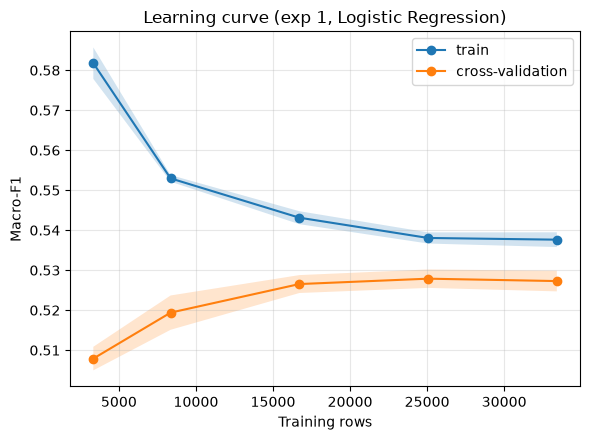

,train_rows,train_f1,cv_f1,gap
0,3341,0.582,0.508,0.074
1,8354,0.553,0.519,0.034
2,16709,0.543,0.527,0.017
3,25063,0.538,0.528,0.010
4,33418,0.538,0.527,0.010


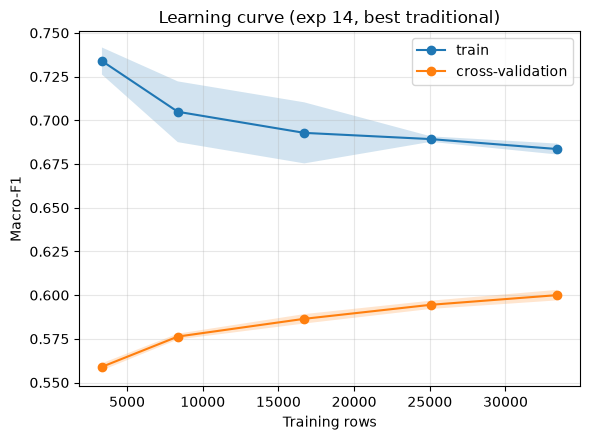

,train_rows,train_f1,cv_f1,gap
0,3341,0.734,0.559,0.175
1,8354,0.705,0.576,0.129
2,16709,0.693,0.586,0.106
3,25063,0.689,0.594,0.095
4,33418,0.684,0.600,0.084


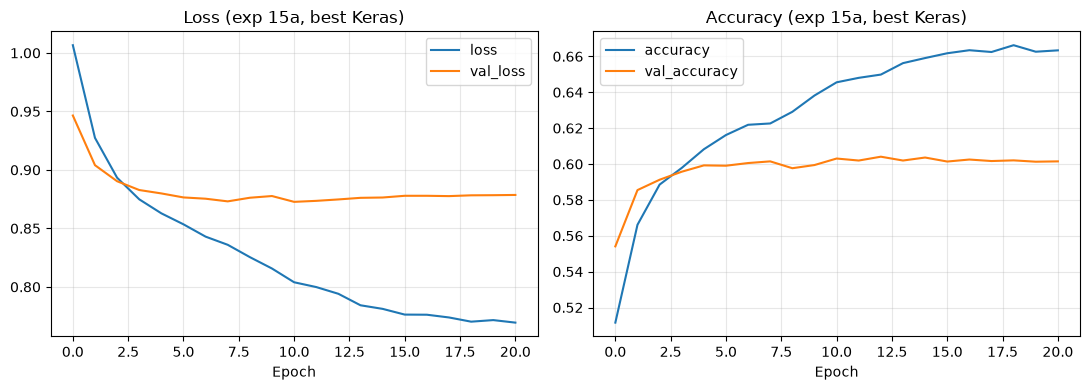

In [40]:
from sklearn.base import clone
from src.evaluation import plot_learning_curve

def unfitted(m):
    # The estimator to refit: the best pipeline found by a search, or the pipeline itself
    return clone(m.best_estimator_ if hasattr(m, "best_estimator_") else m)

_, lc_lr = plot_learning_curve(unfitted(logreg), train, y_train, "(exp 1, Logistic Regression)",
                               name="learning_curve_lr.png", seed=SEED)
plt.show(); display(lc_lr)
_, lc_best = plot_learning_curve(unfitted(best_sk), train, y_train, f"(exp {best_sk_id}, best traditional)",
                                 name="learning_curve_best_sklearn.png", seed=SEED)
plt.show(); display(lc_best)
plot_history(best_dl.history_, f"(exp {best_dl_id}, best Keras)"); plt.show()

**Observation.** - **Logistic regression (exp 1):** the training and CV curves meet at about 0.527-0.538 macro-F1, with a gap of only **0.010** at full size. The CV score is flat from 16,709 rows onward. This is **high bias**: more data will not help a linear model; it needs more flexibility.
- **Gradient boosting (exp 14):** the gap shrinks from 0.175 to **0.084** as data grows, and the CV score is **still rising** (0.559 → 0.600). This is a moderate-variance model that **would gain from more data**.
- **Keras (exp 15a):** best validation loss at epoch 11 of 21 (0.873); training loss keeps falling to 0.769. Early stopping (patience 10) restores the epoch-11 weights, and learning-rate decay keeps the late epochs from drifting. Without decay (exp 7, section 10) validation loss bottomed at epoch 6 and then climbed from 0.852 to 0.935: overfitting, cut off by early stopping.

### 12.2 Confusion matrices (row-normalised)

Each row is a **true** tier and sums to 1, so the diagonal is recall per tier. Errors next to the diagonal (Low↔Mid, Mid↔High) are "one tier off"; the corners (Low↔High) are "far" errors.

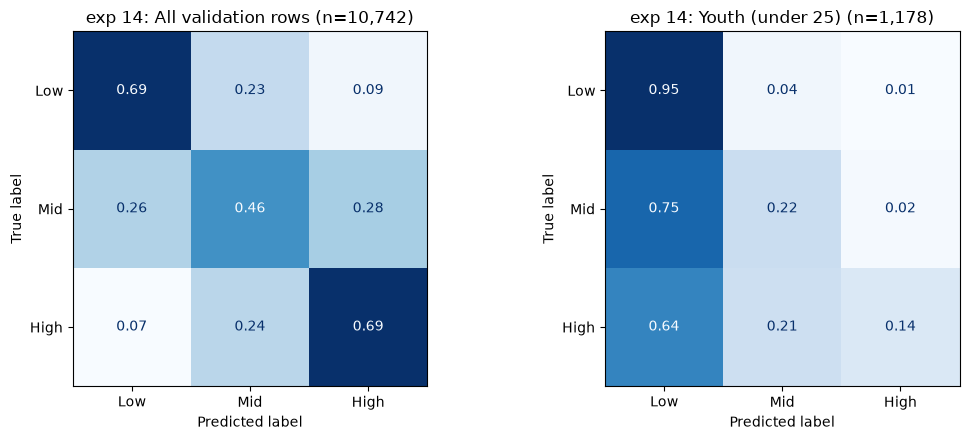

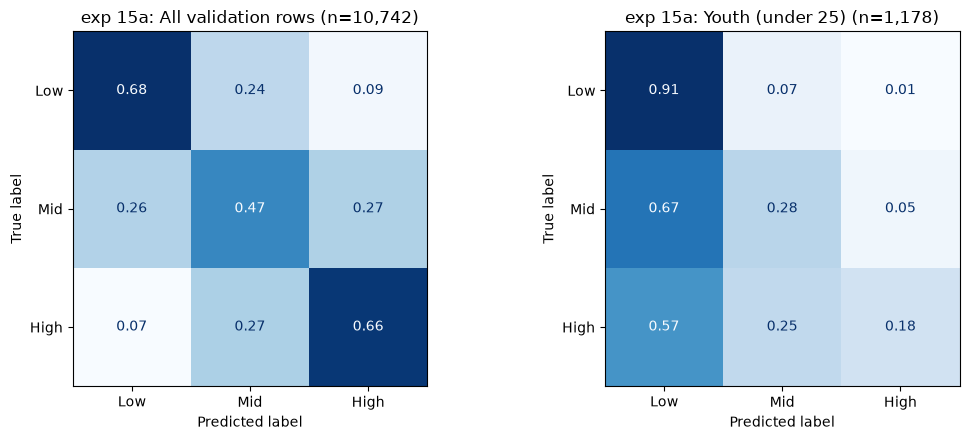

,exp 14,exp 15a
correct,0.609,0.603
one tier off,0.339,0.345
two tiers off,0.053,0.052


In [41]:
from src.evaluation import plot_confusions, plot_roc_pr
youth = val["IsYouth"].to_numpy()
masks = {"All validation rows": np.ones(len(val), bool), "Youth (under 25)": youth}
pred_sk, pred_dl = best_sk.predict(val), best_dl.predict(val)
plot_confusions(y_val, pred_sk, masks, f"exp {best_sk_id}: ", name="confusion_best_sklearn.png"); plt.show()
plot_confusions(y_val, pred_dl, masks, f"exp {best_dl_id}: ", name="confusion_best_keras.png"); plt.show()

def error_profile(pred):
    d = np.abs(y_val.map(TIER_NUM).to_numpy() - pd.Series(pred).astype(str).map(TIER_NUM).to_numpy())
    return pd.Series({"correct": (d == 0).mean(), "one tier off": (d == 1).mean(), "two tiers off": (d == 2).mean()})
from src.evaluation import TIER_NUM
pd.DataFrame({f"exp {best_sk_id}": error_profile(pred_sk), f"exp {best_dl_id}": error_profile(pred_dl)}).round(3)

In [42]:
print("Youth only, best traditional model")
print("Majority-class baseline (always Low):", round((y_val[youth] == "Low").mean(), 3))
print(classification_report(y_val[youth], pred_sk[youth], labels=TIER_ORDER, digits=3))

Youth only, best traditional model
Majority-class baseline (always Low): 0.711
              precision    recall  f1-score   support

         Low      0.763     0.952     0.847       838
         Mid      0.546     0.223     0.317       264
        High      0.458     0.145     0.220        76

    accuracy                          0.737      1178
   macro avg      0.589     0.440     0.461      1178
weighted avg      0.695     0.737     0.688      1178



**Observation.** - **All rows (exp 14):** recall Low 0.685, **Mid 0.455**, High 0.686. Mid's errors split almost evenly (26% to Low, 28% to High), confirming that Mid sits between two similar neighbours. Only **5.3%** of predictions are two tiers off; most errors are one tier away. Keras (exp 15a) has the same structure with slightly better Mid recall (0.475) and 5.2% far errors.
- **Youth (1,178 rows):** exp 14 still predicts Low for most young people: recall Low 0.952, Mid 0.223, **High 0.145**. Its accuracy (0.737) beats the always-Low baseline (0.711), and macro-F1 is 0.461 (up from 0.389 for exp 6g). Keras spreads predictions more (youth recall Mid 0.277, High 0.184; macro-F1 0.477), but both find few of the high-paid young people.
- Why: only 76 young people in validation are High, and in training 71.5% of youth are Low. The tiers compare young people with all developers, including seniors, so a low tier for a 22-year-old mostly reflects seniority, **not underpayment** (experiment 11 confirms this).

### 12.3 ROC and precision-recall curves

One-vs-rest: for each tier, the model's probability for that tier is used to separate it from the other two. AUC 0.5 = random, 1.0 = perfect. Because the classes are balanced, the precision-recall chance level is 1/3 (dashed line).

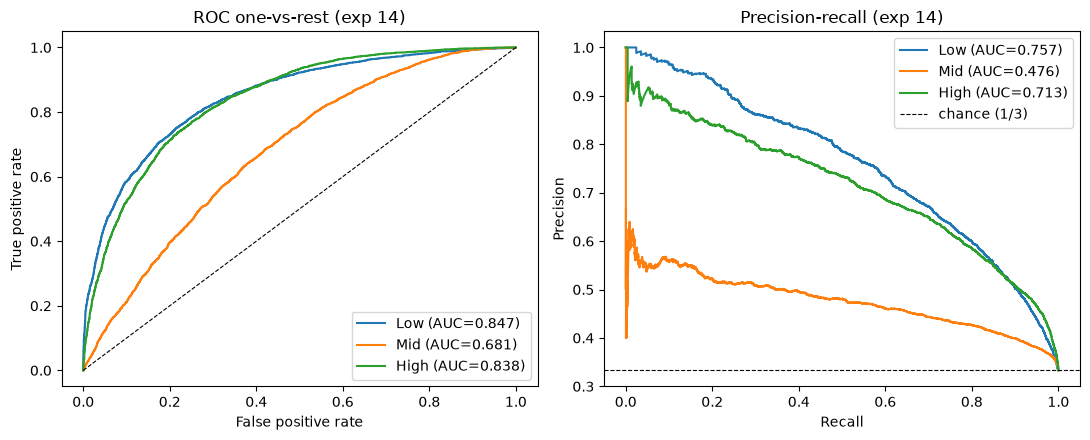

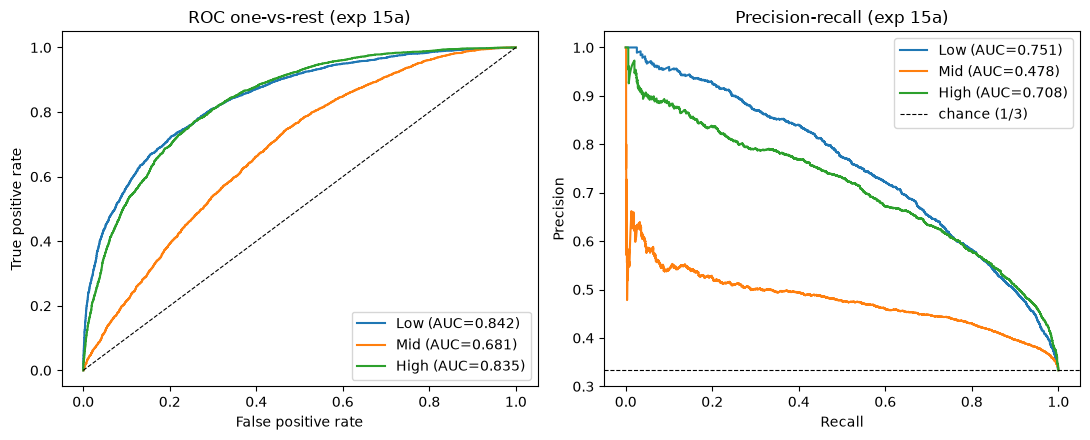

In [43]:
plot_roc_pr(best_sk, val, y_val, f"(exp {best_sk_id})", name="roc_pr_best_sklearn.png"); plt.show()
plot_roc_pr(best_dl, val, y_val, f"(exp {best_dl_id})", name="roc_pr_best_keras.png"); plt.show()

**Observation.** - Per-tier ROC-AUC (exp 14): **Low 0.847, Mid 0.681, High 0.838**. Keras (exp 15a) is almost identical: 0.842 / 0.681 / 0.835. PR-AUC: Low 0.758, Mid 0.476 (Keras 0.478), High 0.713, against a chance level of 0.333.
- The extremes are well separated; Mid is much closer to the diagonal. The models are good at telling a clearly low-paid profile from a clearly high-paid one, and most of the remaining difficulty is the middle tier.

### 12.4 Subgroup performance

Each subgroup is compared with **its own** majority baseline (always predicting the subgroup's most common tier). This matters for youth: most young respondents are Low, so "always Low" already scores well on accuracy.

In [44]:
top_countries = val["Country"].value_counts().index[:6]
country_group = np.where(val["Country"].isin(top_countries), val["Country"],
                np.where(val["Country"].isin(AFRICA), "Africa (ZA, NG)", "Other countries"))
for title, g in [("Survey year", val["Year"]), ("Youth (under 25)", val["IsYouth"]),
                 ("Country group", country_group)]:
    print(title)
    display(pd.concat({f"exp {best_sk_id}": subgroup_table(best_sk, val, y_val, g),
                       f"exp {best_dl_id}": subgroup_table(best_dl, val, y_val, g)[["accuracy", "macro_f1"]]},
                      axis=1))

Survey year


exp 14                                                         exp 15a         
           n accuracy macro_f1 majority_class majority_baseline_acc accuracy macro_f1
group                                                                                
2023    5678    0.605    0.604            Low                 0.342    0.605    0.606
2024    2659    0.608    0.603            Low                 0.357    0.589    0.586
2025    2405    0.619    0.608           High                 0.395    0.613    0.604

Youth (under 25)


exp 14                                                         exp 15a         
           n accuracy macro_f1 majority_class majority_baseline_acc accuracy macro_f1
group                                                                                
False   9564    0.593    0.592           High                 0.367    0.588    0.589
True    1178    0.737    0.461            Low                 0.711    0.723    0.477

Country group


exp 14                                                         exp 15a         
                                                        n accuracy macro_f1 majority_class majority_baseline_acc accuracy macro_f1
group                                                                                                                             
Africa (ZA, NG)                                       122    0.623    0.615           High                 0.402    0.648    0.652
Canada                                                482    0.660    0.659            Mid                 0.357    0.643    0.645
France                                                420    0.610    0.607           High                 0.357    0.602    0.600
Germany                                               893    0.627    0.623           High                 0.340    0.622    0.620
India                                                 498    0.665    0.657            Low                 0.357    0.655    0.651
Other countries                                      4769    0.578    0.575            Low                 0.337    0.575    0.574
United Kingdom of Great Britain and Northern Ir...    807    0.644    0.645            Mid                 0.341    0.617    0.618
United States of America                             2751    0.626    0.624            Mid                 0.337    0.624    0.623

**Observation.** - **Year:** macro-F1 0.604 (2023), 0.603 (2024), 0.608 (2025) for exp 14. The model is now almost equally good in every year (spread 0.5 points, against 2.2 points for exp 6g), so the new features did not make the model lean on one survey year. Each year's baseline is 34-40%.
- **Youth:** see 12.2; on accuracy exp 14 beats always-Low by 2.6 points (0.737 vs 0.711), and the larger gain shows in macro-F1.
- **Countries:** the large markets score 0.61-0.67 accuracy (each baseline about 0.34-0.36), with India (0.665) and Canada (0.660) highest. The long tail of smaller countries ("Other", 4,769 rows) is weakest at 0.578. South Africa and Nigeria together (122 validation rows) score 0.623 (Keras 0.648), but 122 rows give a margin of roughly ±9 points, so this is indicative only.

### 12.5 What separates Low from High?

**(a) Logistic-regression coefficients (exp 1).** For each feature, the High coefficient minus the Low coefficient: positive = associated with the High tier, negative = with the Low tier, **holding the other features fixed**. Numeric features are standardised, so their coefficient is per standard deviation; skills are 0/1.

**(b) Permutation importance (best traditional model).** Each input column is shuffled in turn on the validation set and the drop in macro-F1 is measured. A large drop means the model relies on that column. Columns are permuted as whole survey questions (e.g. all languages together), which is easier to interpret than single tokens.

**(c) The same on the experience-adjusted label (exp 11)**, which shows what matters *after* seniority is largely removed. This is the view most relevant to the mission.

**Caution.** These are **associations** in a self-selected survey, not causes. "Developers who use X earn more" does not mean that learning X raises pay.

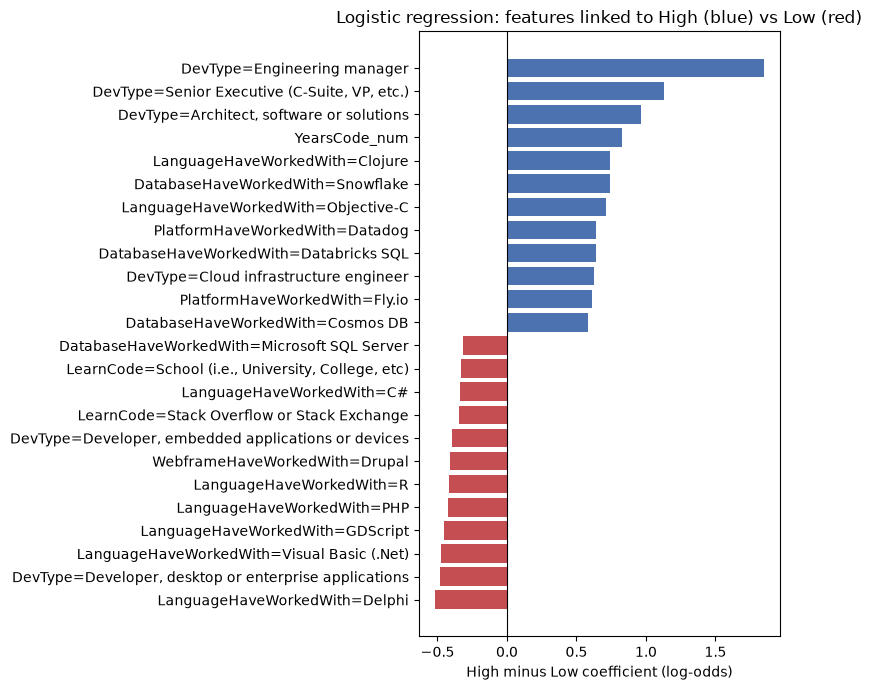

In [45]:
lr_clf, lr_pre = logreg.named_steps["clf"], logreg.named_steps["pre"]
cls = list(lr_clf.classes_)
contrast = pd.Series(lr_clf.coef_[cls.index("High")] - lr_clf.coef_[cls.index("Low")],
                     index=[n.split("__", 1)[1] for n in lr_pre.get_feature_names_out()])
top = pd.concat([contrast.nlargest(12), contrast.nsmallest(12)]).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#4C72B0", "#C44E52"))
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="High minus Low coefficient (log-odds)",
       title="Logistic regression: features linked to High (blue) vs Low (red)")
plt.tight_layout(); plt.savefig(f"{FIG}/lr_coefficients.png", dpi=200); plt.show()

,main label (exp 14),experience-adjusted (exp 11)
YearsCode_num,0.0527,0.0442
WorkExp_num,0.0471,0.0432
Country,0.0359,0.0092
OrgSize,0.0299,0.0271
OpSysProfessional use,0.0228,0.0000
LanguageHaveWorkedWith,0.0164,0.0206
OfficeStackAsyncHaveWorkedWith,0.0131,0.0000
Industry,0.0127,0.0116
DatabaseHaveWorkedWith,0.0095,0.0107
Age_num,0.0087,0.0096


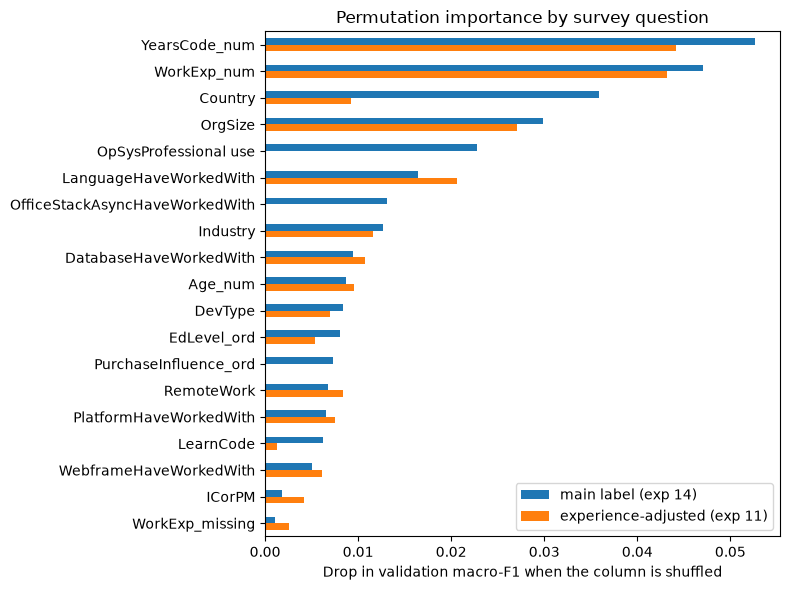

In [46]:
from sklearn.inspection import permutation_importance
from src.pipeline import NUMERIC

def raw_importance(model, X, y, cols):
    r = permutation_importance(model, X[cols], y, scoring="f1_macro", n_repeats=5,
                               random_state=SEED, n_jobs=2)
    return pd.Series(r.importances_mean, index=cols).sort_values(ascending=False)

from src.pipeline import EXTRA_NUMERIC, EXTRA_MULTI
input_cols = NUMERIC + EXTRA_NUMERIC + MULTI + EXTRA_MULTI + list(JOB_CONTEXT) + ["Country"]
imp_main = raw_importance(best_sk, val, y_val, input_cols)
imp_exp = raw_importance(exp_model, val11, val11["PayTierExp"].astype(str), input_cols)
imp = pd.DataFrame({f"main label (exp {best_sk_id})": imp_main,
                    "experience-adjusted (exp 11)": imp_exp}).round(4)
imp = imp[(imp != 0).any(axis=1)].sort_values(imp.columns[0], ascending=False)
display(imp)
imp.plot.barh(figsize=(8, 6)).invert_yaxis()
plt.xlabel("Drop in validation macro-F1 when the column is shuffled")
plt.title("Permutation importance by survey question")
plt.tight_layout(); plt.savefig(f"{FIG}/permutation_importance.png", dpi=200); plt.show()

**Observation.** - **Experience dominates** both views: shuffling `YearsCode_num` or `WorkExp_num` costs about 0.05 macro-F1 each on the main label, and still 0.04 on the experience-adjusted label.
- **Country** matters for the main label (0.036) but much less once experience is held constant (0.009), consistent with the interaction explanation in exp 6.
- **After experience, what separates pay is the employer and the work setting:** `OrgSize` (0.030 main / 0.027 adjusted), operating systems used at work (0.023), languages (0.016 / 0.021), office tools (0.013), industry and databases. Education (0.008 / 0.005), purchase influence (0.007) and how someone learned to code (0.006 / 0.001) add least. (The exp 11 model does not use the three columns added in exp 14, hence 0 there.)
- **Logistic-regression contrasts (High vs Low, exp 1):** the strongest High associations are roles (engineering manager +1.85, C-suite +1.13, architect +0.96, cloud infrastructure engineer +0.63), years coding (+0.82 per standard deviation) and data/cloud tools (Snowflake, Databricks SQL, Datadog, Cosmos DB, Clojure). The strongest Low associations are legacy or enterprise-desktop stacks (Delphi, VB.NET, desktop/enterprise and embedded developer roles, PHP, Drupal, C#, MS SQL Server), R and GDScript. These are **associations**: they partly reflect which companies and countries use these tools.

### 12.6 Who is predicted a higher tier than they report?

**Why.** If a model built on skills and experience predicts a higher tier than someone reports, their profile looks like that of better-paid peers. This is the closest the data gets to the "underpayment" angle of the mission.

**Strong caveats.** It is **not** evidence that these people are underpaid. Salaries are self-reported; the model misses many pay drivers (negotiation, city, company, performance, hours); and the model is wrong 40-50% of the time anyway. Treat this as a description of where the model and reported pay disagree.

In [47]:
rank_true = y_val.map(TIER_NUM).to_numpy()
rank_pred = pd.Series(pred_sk).astype(str).map(TIER_NUM).to_numpy()
group = np.select([rank_pred > rank_true, rank_pred < rank_true], ["predicted higher", "predicted lower"], "correct")

prof = val.assign(group=group, remote=val["RemoteWork"].fillna("").str.startswith("Remote"),
                  n_languages=val["LanguageHaveWorkedWith"].fillna("").str.count(";") + 1)
summary = prof.groupby("group").agg(
    n=("group", "size"), youth_share=("IsYouth", "mean"),
    median_years_coding=("YearsCode_num", "median"), mean_education=("EdLevel_ord", "mean"),
    remote_share=("remote", "mean"), median_languages=("n_languages", "median"),
    median_salary_usd=("ConvertedCompYearly", "median"))
display(summary.round(2))
print("True tier of 'predicted higher' rows:\n", y_val[group == "predicted higher"].value_counts(normalize=True).round(3))

,n,youth_share,median_years_coding,mean_education,remote_share,median_languages,median_salary_usd
group,,,,,,,
correct,6540,0.13,13.0,4.93,0.40,5.0,80000.0
predicted higher,2134,0.02,16.0,5.08,0.47,5.0,64444.0
predicted lower,2068,0.13,11.0,4.92,0.37,5.0,86124.0


True tier of 'predicted higher' rows:
 PayTier
Low    0.528
Mid    0.472
Name: proportion, dtype: float64


**Observation.** - 2,134 validation rows (20%) are predicted a higher tier than they report; 53% of them report Low, 47% Mid.
- Compared with correctly predicted rows, they are **experienced** (median 16 years coding vs 13), slightly more educated (4.93 → 5.08), **more often fully remote** (47% vs 40%), and report a **lower median salary** ($64,444 vs $80,000). **Only 2% are young.**
- So the group whose profile "looks better paid than reported" is mostly mid-career, often remote developers, not young people. Many explanations fit: part-time hours within "employed", remote pay set by cheaper markets, smaller employers, or simply the model's error. This does **not** show that anyone is underpaid.

### 12.7 East Africa and Rwanda: descriptive case study

**Why only descriptive.** These countries were removed by the 100-rows-per-country rule, so they have no reliable within-country tercile and the model never saw them. We apply the final traditional model to the respondents who pass every other filter and report counts only. **No statistical claim can be made from a handful of rows.**

In [48]:
strict_all, _ = filter_respondents(df)
EAST = ["Rwanda", "Kenya", "Uganda", "Tanzania", "Ethiopia"]
africa_out = add_basic_features(strict_all[strict_all["Country"].isin(AFRICA)
                                           & ~strict_all["Country"].isin(data["Country"].unique())])
africa_out = africa_out.assign(predicted=best_sk.predict(africa_out),
                               region=np.where(africa_out["Country"].isin(EAST), "East Africa", "Other Africa"))
case = africa_out.groupby("Country").agg(n=("predicted", "size"), youth=("IsYouth", "sum"),
                                         median_salary_usd=("ConvertedCompYearly", "median"))
case = case.join(pd.crosstab(africa_out["Country"], africa_out["predicted"]).reindex(columns=TIER_ORDER, fill_value=0))
case

,n,youth,median_salary_usd,Low,Mid,High
Country,,,,,,
Ethiopia,32,6,11500.5,22,8,2
Ghana,28,5,7727.0,16,11,1
Kenya,89,19,16861.0,52,20,17
Rwanda,11,4,13616.0,6,2,3
Uganda,18,3,9654.0,13,4,1


**Observation.** - Respondents passing every filter except the country-size rule: **Kenya 89, Ethiopia 32, Ghana 28, Uganda 18, Rwanda 11** (Rwanda: 4 of the 11 are young; median reported salary $13,616).
- The model predicts mostly Low (Rwanda: 6 Low, 2 Mid, 3 High). Two cautions make this **purely descriptive**: (1) these countries were never seen in training, so the `Country` feature is unknown to the model, and their "tier" is relative to an unknown local market; (2) 11 rows cannot support any statistical claim.
- What it does show: the profiles of East African respondents look like the profiles the model associates with lower relative pay elsewhere, which motivates collecting larger regional data (future work).

## 15. Reproducibility proof

**What happens.** Experiment 1 (logistic regression) and experiment 7 (Keras MLP) are **refitted from scratch** with `force=True`, using exactly the same settings. The tracker prints the largest difference between the new metrics and the saved ones. A difference of 0 (or ~1e-16) proves that the pipeline, seeds and saved results agree. For Keras this relies on `enable_op_determinism()`.

In [49]:
tracker.run(1, "Logistic Regression",
    Pipeline([("pre", build_preprocessor()),
              ("clf", LogisticRegression(max_iter=2000, random_state=SEED))]),
    settings={"features": "core", "C": 1.0}, note="interpretable benchmark", force=True)
ktracker.run(7, "Keras Sequential MLP",
    KerasPipeline(kind="mlp", pre_kwargs=DL_PRE, hidden=(256, 128), dropout=0.3,
                  lr=1e-3, batch_size=256, epochs=100, patience=8, seed=SEED),
    settings={"arch": "Dense256-Drop0.3-Dense128-Drop0.3-Softmax3", "lr": 1e-3,
              "batch": 256, "early_stopping": "val_loss, patience 8"},
    note="first deep model", force=True);

[exp 1] fitted in 6.7s


[exp 1] largest metric difference vs saved run: 0.00e+00 (train_accuracy)


[exp 7] fitted in 27.3s


[exp 7] largest metric difference vs saved run: 0.00e+00 (train_accuracy)


**Observation.** Both refits from scratch reproduce the saved metrics exactly: **largest difference 0.00e+00** for logistic regression (exp 1) and for the Keras MLP (exp 7). The seeds, the deterministic TensorFlow ops and the saved results agree, so every number in the experiment table can be regenerated.